In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set random seed for reproducibility
RANDOM_STATE = 42
warnings.filterwarnings('ignore')

In [2]:
# Load the traffic dataset from an Excel or CSV file

file_path = "Dataset_Uber_Traffic_Combined.xlsx"  

if file_path.endswith(".csv"):
    df = pd.read_csv(file_path)
else:
    df = pd.read_excel(file_path)

In [3]:
# Display the first five records to understand the data
print(df.head())

             DateTime  Junction  Vehicles           ID  temperature_2m (°C)  \
0 2015-11-01 00:00:00         1        15  20151101001                 20.8   
1 2015-11-01 00:00:00         2         6  20151101002                 20.8   
2 2015-11-01 01:00:00         1        13  20151101011                 20.6   
3 2015-11-01 01:00:00         2         6  20151101012                 20.6   
4 2015-11-01 02:00:00         1        10  20151101021                 22.1   

   relative_humidity_2m (%)  precipitation (mm)  rain (mm)  
0                        83                 0.0        0.0  
1                        83                 0.0        0.0  
2                        83                 0.0        0.0  
3                        83                 0.0        0.0  
4                        76                 0.0        0.0  


In [4]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (48120, 8)


In [5]:
df.shape

(48120, 8)

In [6]:
# Display column names
print("Columns:", df.columns.tolist())

Columns: ['DateTime', 'Junction', 'Vehicles', 'ID', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'precipitation (mm)', 'rain (mm)']


In [7]:
df.describe()

,DateTime,Junction,Vehicles,ID,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
count,48120,48120.000000,48120.000000,4.812000e+04,48120.000000,48120.000000,48120.000000,48120.000000
mean,2016-09-19 06:03:56.109725,2.180549,22.791334,2.016330e+10,26.474944,55.798109,0.078387,0.078387
min,2015-11-01 00:00:00,1.000000,1.000000,2.015110e+10,12.400000,8.000000,0.000000,0.000000
25%,2016-04-16 01:45:00,1.000000,9.000000,2.016042e+10,22.900000,36.000000,0.000000,0.000000
50%,2016-09-30 03:30:00,2.000000,15.000000,2.016093e+10,26.100000,56.000000,0.000000,0.000000
75%,2017-02-25 16:00:00,3.000000,29.000000,2.017023e+10,29.600000,75.000000,0.000000,0.000000
max,2017-06-30 23:00:00,4.000000,180.000000,2.017063e+10,41.400000,99.000000,9.400000,9.400000
std,NaN,0.966955,20.750063,5.944854e+06,5.343974,22.852496,0.392051,0.392051


In [8]:
# Check column data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DateTime                  48120 non-null  datetime64[us]
 1   Junction                  48120 non-null  int64         
 2   Vehicles                  48120 non-null  int64         
 3   ID                        48120 non-null  int64         
 4   temperature_2m (°C)       48120 non-null  float64       
 5   relative_humidity_2m (%)  48120 non-null  int64         
 6   precipitation (mm)        48120 non-null  float64       
 7   rain (mm)                 48120 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(4)
memory usage: 2.9 MB


In [9]:
print(df.isnull().sum())

DateTime                    0
Junction                    0
Vehicles                    0
ID                          0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
rain (mm)                   0
dtype: int64


# this provides there are no null values in the dataset

In [10]:
# Convert column names to lowercase and replace spaces with underscores

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Updated Column Names:")
print(df.columns.tolist())

Updated Column Names:
['datetime', 'junction', 'vehicles', 'id', 'temperature_2m_c', 'relative_humidity_2m', 'precipitation_mm', 'rain_mm']


In [11]:
# Identify timestamp, junction, and vehicle count columns

print(df.columns.tolist())

timestamp_col = "datetime"
junction_col = "junction"
vehicle_col = "vehicles"

# Verify that the required columns exist
required_columns = [timestamp_col, junction_col, vehicle_col]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Column '{col}' not found. Check your dataset.")

print("\nRequired columns identified successfully.")

['datetime', 'junction', 'vehicles', 'id', 'temperature_2m_c', 'relative_humidity_2m', 'precipitation_mm', 'rain_mm']

Required columns identified successfully.


In [12]:
# Convert timestamp and vehicle count columns to appropriate data types

df[timestamp_col] = pd.to_datetime(
    df[timestamp_col],
    errors="coerce"
)

df[vehicle_col] = pd.to_numeric(
    df[vehicle_col],
    errors="coerce"
)

# Remove rows with missing essential values
df = df.dropna(
    subset=[timestamp_col, junction_col, vehicle_col]
).copy()

# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert junction identifiers to strings
df[junction_col] = df[junction_col].astype("string")

# Remove negative vehicle counts
df = df[df[vehicle_col] >= 0].copy()

# Fill missing values in other numeric columns using the median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if col != vehicle_col:
        df[col] = df[col].fillna(df[col].median())


In [13]:
# Display the cleaned dataset
print("Shape After Cleaning:", df.shape)
display(df.head())

Shape After Cleaning: (48120, 8)


,datetime,junction,vehicles,id,temperature_2m_c,relative_humidity_2m,precipitation_mm,rain_mm
0,2015-11-01 00:00:00,1,15,20151101001,20.8,83,0.0,0.0
1,2015-11-01 00:00:00,2,6,20151101002,20.8,83,0.0,0.0
2,2015-11-01 01:00:00,1,13,20151101011,20.6,83,0.0,0.0
3,2015-11-01 01:00:00,2,6,20151101012,20.6,83,0.0,0.0
4,2015-11-01 02:00:00,1,10,20151101021,22.1,76,0.0,0.0


In [14]:
print("Missing Values:")
display(df.isnull().sum())

Missing Values:


datetime                0
junction                0
vehicles                0
id                      0
temperature_2m_c        0
relative_humidity_2m    0
precipitation_mm        0
rain_mm                 0
dtype: int64

In [15]:
# Round timestamps down to the nearest hour

df["hour_timestamp"] = df[timestamp_col].dt.floor("h")

# Aggregate vehicle counts for each junction and hour
hourly_df = (
    df.groupby([junction_col, "hour_timestamp"], as_index=False)
    .agg({vehicle_col: "sum"})
)

# Rename timestamp column
hourly_df = hourly_df.rename(
    columns={"hour_timestamp": "datetime"}
)

# Sort records chronologically for each junction
hourly_df = hourly_df.sort_values(
    [junction_col, "datetime"]
).reset_index(drop=True)


In [16]:
# Display hourly aggregated traffic data
print(hourly_df.head(10))

  junction            datetime  vehicles
0        1 2015-11-01 00:00:00        15
1        1 2015-11-01 01:00:00        13
2        1 2015-11-01 02:00:00        10
3        1 2015-11-01 03:00:00         7
4        1 2015-11-01 04:00:00         9
5        1 2015-11-01 05:00:00         6
6        1 2015-11-01 06:00:00         9
7        1 2015-11-01 07:00:00         8
8        1 2015-11-01 08:00:00        11
9        1 2015-11-01 09:00:00        12


In [17]:
print("Hourly Dataset Shape:", hourly_df.shape)

Hourly Dataset Shape: (48120, 3)


In [18]:
# Standardize vehicle counts using StandardScaler

scaler = StandardScaler()

hourly_df["vehicle_count_standardized"] = scaler.fit_transform(
    hourly_df[[vehicle_col]]
)

# Display original and standardized values
display(
    hourly_df[
        [junction_col, "datetime", vehicle_col,
         "vehicle_count_standardized"]
    ].head()
)

,junction,datetime,vehicles,vehicle_count_standardized
0,1,2015-11-01 00:00:00,15,-0.375489
1,1,2015-11-01 01:00:00,13,-0.471875
2,1,2015-11-01 02:00:00,10,-0.616454
3,1,2015-11-01 03:00:00,7,-0.761034
4,1,2015-11-01 04:00:00,9,-0.664648


In [19]:
# Extract time-related features from the timestamp

hourly_df["hour"] = hourly_df["datetime"].dt.hour

hourly_df["day_of_week"] = hourly_df["datetime"].dt.dayofweek

hourly_df["day_of_month"] = hourly_df["datetime"].dt.day

hourly_df["month"] = hourly_df["datetime"].dt.month

hourly_df["year"] = hourly_df["datetime"].dt.year

hourly_df["day_of_year"] = hourly_df["datetime"].dt.dayofyear

# Identify weekends (Saturday = 5, Sunday = 6)
hourly_df["is_weekend"] = (
    hourly_df["day_of_week"] >= 5
).astype(int)

# Identify morning and evening rush hours
hourly_df["is_morning_rush"] = (
    hourly_df["hour"].between(7, 10)
).astype(int)

hourly_df["is_evening_rush"] = (
    hourly_df["hour"].between(16, 19)
).astype(int)

# Display the new features
display(hourly_df.head())

,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,is_weekend,is_morning_rush,is_evening_rush
0,1,2015-11-01 00:00:00,15,-0.375489,0,6,1,11,2015,305,1,0,0
1,1,2015-11-01 01:00:00,13,-0.471875,1,6,1,11,2015,305,1,0,0
2,1,2015-11-01 02:00:00,10,-0.616454,2,6,1,11,2015,305,1,0,0
3,1,2015-11-01 03:00:00,7,-0.761034,3,6,1,11,2015,305,1,0,0
4,1,2015-11-01 04:00:00,9,-0.664648,4,6,1,11,2015,305,1,0,0


In [20]:
# Add dates of relevant local holidays, festivals, or special events.
# Replace these example dates with verified event dates.

special_event_dates = [
    # "2026-08-15",
    # "2026-10-20"
]

special_event_dates = pd.to_datetime(
    special_event_dates
).normalize()

# Mark records occurring on special event dates
hourly_df["is_special_event"] = (
    hourly_df["datetime"].dt.normalize()
    .isin(special_event_dates)
).astype(int)

display(
    hourly_df[
        ["datetime", "is_weekend", "is_special_event"]
    ].head()
)

,datetime,is_weekend,is_special_event
0,2015-11-01 00:00:00,1,0
1,2015-11-01 01:00:00,1,0
2,2015-11-01 02:00:00,1,0
3,2015-11-01 03:00:00,1,0
4,2015-11-01 04:00:00,1,0


In [21]:
# Sort records before calculating lag features
hourly_df = hourly_df.sort_values(
    [junction_col, "datetime"]
).reset_index(drop=True)

# Capture traffic counts from previous hours
for lag in [1, 2, 3, 6, 12, 24]:
    hourly_df[f"vehicle_count_lag_{lag}h"] = (
        hourly_df.groupby(junction_col)[vehicle_col].shift(lag)
    )

# Calculate rolling averages using previous observations only
hourly_df["rolling_mean_3h"] = (
    hourly_df.groupby(junction_col)[vehicle_col]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

hourly_df["rolling_mean_24h"] = (
    hourly_df.groupby(junction_col)[vehicle_col]
    .transform(lambda x: x.shift(1).rolling(24).mean())
)

# Display lag features
display(hourly_df.head(30))

,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,is_evening_rush,is_special_event,vehicle_count_lag_1h,vehicle_count_lag_2h,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h
0,1,2015-11-01 00:00:00,15,-0.375489,0,6,1,11,2015,305,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2015-11-01 01:00:00,13,-0.471875,1,6,1,11,2015,305,...,0,0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,2015-11-01 02:00:00,10,-0.616454,2,6,1,11,2015,305,...,0,0,13.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN
3,1,2015-11-01 03:00:00,7,-0.761034,3,6,1,11,2015,305,...,0,0,10.0,13.0,15.0,NaN,NaN,NaN,12.666667,NaN
4,1,2015-11-01 04:00:00,9,-0.664648,4,6,1,11,2015,305,...,0,0,7.0,10.0,13.0,NaN,NaN,NaN,10.000000,NaN
5,1,2015-11-01 05:00:00,6,-0.809227,5,6,1,11,2015,305,...,0,0,9.0,7.0,10.0,NaN,NaN,NaN,8.666667,NaN
6,1,2015-11-01 06:00:00,9,-0.664648,6,6,1,11,2015,305,...,0,0,6.0,9.0,7.0,15.0,NaN,NaN,7.333333,NaN
7,1,2015-11-01 07:00:00,8,-0.712841,7,6,1,11,2015,305,...,0,0,9.0,6.0,9.0,13.0,NaN,NaN,8.000000,NaN
8,1,2015-11-01 08:00:00,11,-0.568261,8,6,1,11,2015,305,...,0,0,8.0,9.0,6.0,10.0,NaN,NaN,7.666667,NaN
9,1,2015-11-01 09:00:00,12,-0.520068,9,6,1,11,2015,305,...,0,0,11.0,8.0,9.0,7.0,NaN,NaN,9.333333,NaN


In [22]:
# Convert junction categories into binary indicator columns

junction_dummies = pd.get_dummies(
    hourly_df[junction_col],
    prefix="junction",
    dtype=int
)

hourly_df = pd.concat(
    [hourly_df, junction_dummies],
    axis=1
)

display(hourly_df.head())

,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h,junction_1,junction_2,junction_3,junction_4
0,1,2015-11-01 00:00:00,15,-0.375489,0,6,1,11,2015,305,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0
1,1,2015-11-01 01:00:00,13,-0.471875,1,6,1,11,2015,305,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0
2,1,2015-11-01 02:00:00,10,-0.616454,2,6,1,11,2015,305,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0
3,1,2015-11-01 03:00:00,7,-0.761034,3,6,1,11,2015,305,...,15.0,NaN,NaN,NaN,12.666667,NaN,1,0,0,0
4,1,2015-11-01 04:00:00,9,-0.664648,4,6,1,11,2015,305,...,13.0,NaN,NaN,NaN,10.000000,NaN,1,0,0,0


In [23]:
# Remove rows with missing lag features
# These rows lack sufficient historical observations.

lag_columns = [
    "vehicle_count_lag_1h",
    "vehicle_count_lag_2h",
    "vehicle_count_lag_3h",
    "vehicle_count_lag_6h",
    "vehicle_count_lag_12h",
    "vehicle_count_lag_24h",
    "rolling_mean_3h",
    "rolling_mean_24h"
]

model_df = hourly_df.dropna(
    subset=lag_columns
).copy()

print("Modeling Dataset Shape:", model_df.shape)

display(model_df.head())

Modeling Dataset Shape: (48024, 26)


,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h,junction_1,junction_2,junction_3,junction_4
24,1,2015-11-02 00:00:00,14,-0.423682,0,0,2,11,2015,306,...,19.0,17.0,16.0,15.0,18.000000,13.625000,1,0,0,0
25,1,2015-11-02 01:00:00,12,-0.520068,1,0,2,11,2015,306,...,20.0,20.0,15.0,13.0,16.333333,13.583333,1,0,0,0
26,1,2015-11-02 02:00:00,14,-0.423682,2,0,2,11,2015,306,...,15.0,17.0,16.0,10.0,13.666667,13.541667,1,0,0,0
27,1,2015-11-02 03:00:00,12,-0.520068,3,0,2,11,2015,306,...,14.0,19.0,12.0,7.0,13.333333,13.708333,1,0,0,0
28,1,2015-11-02 04:00:00,12,-0.520068,4,0,2,11,2015,306,...,12.0,20.0,12.0,9.0,12.666667,13.916667,1,0,0,0


In [24]:
# Remove rows with missing lag features
# These rows lack sufficient historical observations.

lag_columns = [
    "vehicle_count_lag_1h",
    "vehicle_count_lag_2h",
    "vehicle_count_lag_3h",
    "vehicle_count_lag_6h",
    "vehicle_count_lag_12h",
    "vehicle_count_lag_24h",
    "rolling_mean_3h",
    "rolling_mean_24h"
]

model_df = hourly_df.dropna(
    subset=lag_columns
).copy()

print("Modeling Dataset Shape:", model_df.shape)

display(model_df.head())

Modeling Dataset Shape: (48024, 26)


,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h,junction_1,junction_2,junction_3,junction_4
24,1,2015-11-02 00:00:00,14,-0.423682,0,0,2,11,2015,306,...,19.0,17.0,16.0,15.0,18.000000,13.625000,1,0,0,0
25,1,2015-11-02 01:00:00,12,-0.520068,1,0,2,11,2015,306,...,20.0,20.0,15.0,13.0,16.333333,13.583333,1,0,0,0
26,1,2015-11-02 02:00:00,14,-0.423682,2,0,2,11,2015,306,...,15.0,17.0,16.0,10.0,13.666667,13.541667,1,0,0,0
27,1,2015-11-02 03:00:00,12,-0.520068,3,0,2,11,2015,306,...,14.0,19.0,12.0,7.0,13.333333,13.708333,1,0,0,0
28,1,2015-11-02 04:00:00,12,-0.520068,4,0,2,11,2015,306,...,12.0,20.0,12.0,9.0,12.666667,13.916667,1,0,0,0


In [25]:
# Calculate correlations between numeric features

numeric_df = model_df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

# Rank features by their correlation with vehicle count
target_correlation = (
    correlation_matrix[vehicle_col]
    .drop(vehicle_col)
    .sort_values(key=abs, ascending=False)
)

print("Feature Correlations with Vehicle Count:")
display(target_correlation.to_frame(name="correlation"))

Feature Correlations with Vehicle Count:


,correlation
vehicle_count_standardized,1.000000
vehicle_count_lag_1h,0.970122
rolling_mean_3h,0.949120
vehicle_count_lag_2h,0.937090
vehicle_count_lag_24h,0.905146
vehicle_count_lag_3h,0.901064
rolling_mean_24h,0.880168
vehicle_count_lag_6h,0.783709
junction_1,0.708336
vehicle_count_lag_12h,0.687973


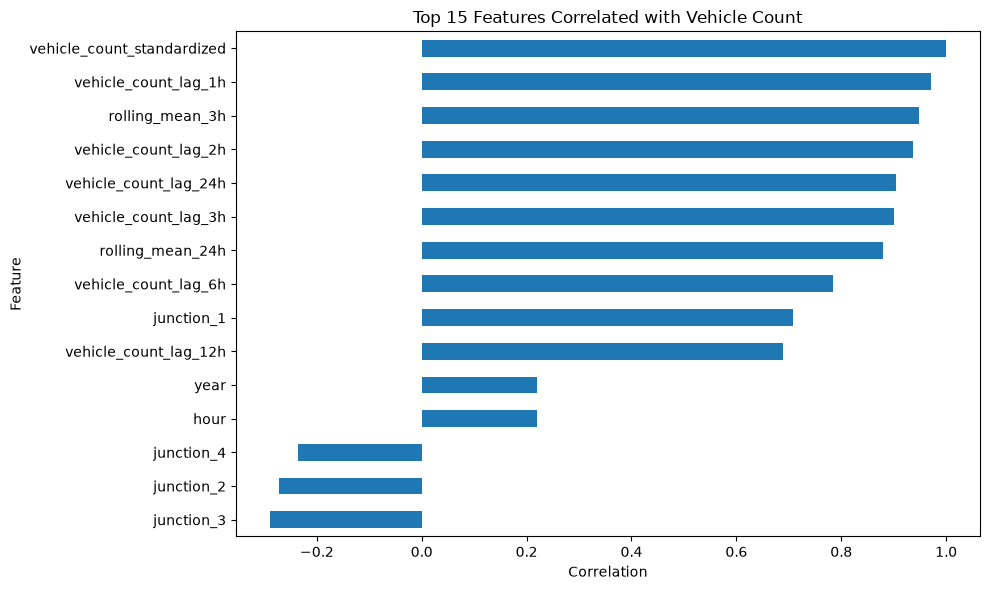

In [26]:
# Plot the top 15 correlated features
top_correlations = target_correlation.head(15).sort_values()

plt.figure(figsize=(10, 6))

top_correlations.plot(kind="barh")

plt.title("Top 15 Features Correlated with Vehicle Count")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

,Feature,Importance
0,vehicle_count_standardized,9.999965e-01
11,vehicle_count_lag_1h,6.487884e-07
17,rolling_mean_3h,6.393650e-07
14,vehicle_count_lag_6h,5.250609e-07
13,vehicle_count_lag_3h,4.511536e-07
15,vehicle_count_lag_12h,2.653425e-07
12,vehicle_count_lag_2h,2.473065e-07
1,hour,1.922259e-07
3,day_of_month,1.450175e-07
18,rolling_mean_24h,1.066685e-07


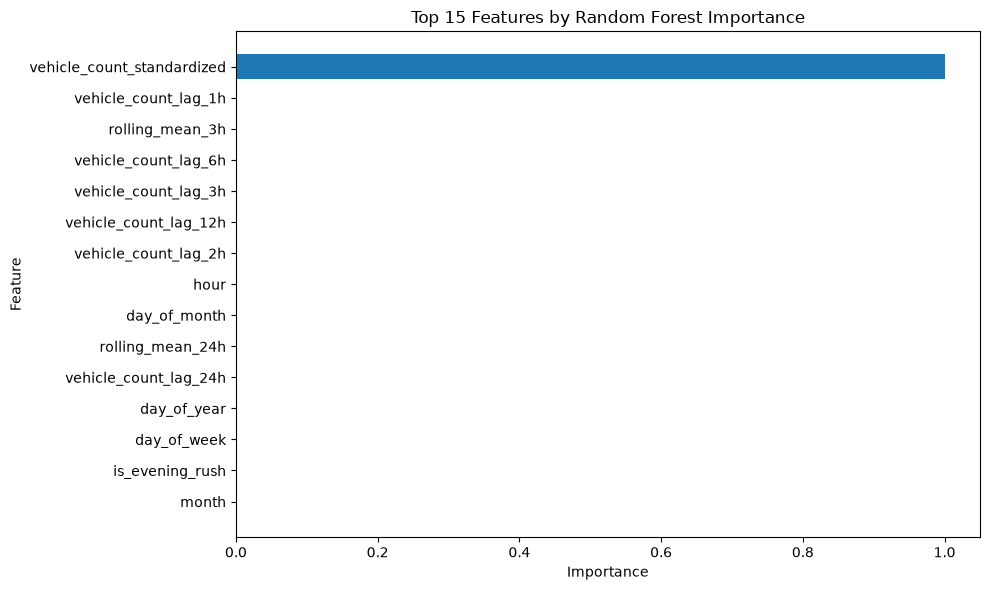

In [27]:
# Prepare features and target variable

excluded_columns = [
    vehicle_col,
    "datetime",
    junction_col,
    timestamp_col
]

feature_columns = [
    col for col in model_df.select_dtypes(include=np.number).columns
    if col not in excluded_columns
]

X = model_df[feature_columns]
y = model_df[vehicle_col]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train a Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    min_samples_leaf=2,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Calculate feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

# Visualize the top 15 important features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features by Random Forest Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [28]:
# Select features whose importance is at least the mean importance

selector = SelectFromModel(
    rf_model,
    threshold="mean",
    prefit=True
)

selected_features = X.columns[selector.get_support()].tolist()

print("Original Number of Features:", len(feature_columns))
print("Selected Number of Features:", len(selected_features))

print("\nSelected Features:")
print(selected_features)

# Create datasets containing only the selected features
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

display(X_train_selected.head())

Original Number of Features: 23
Selected Number of Features: 1

Selected Features:
['vehicle_count_standardized']


,vehicle_count_standardized
24,-0.423682
25,-0.520068
26,-0.423682
27,-0.520068
28,-0.520068


In [29]:
# Prepare hourly traffic and weather data

# Identify available weather columns in the original cleaned dataset
weather_columns = [
    "temperature_2m_c",
    "relative_humidity_2m",
    "precipitation_mm",
    "rain_mm",
    "wind_speed_10m_kmh"
]

weather_columns = [
    col for col in weather_columns
    if col in df.columns
]

print("Available Weather Columns:", weather_columns)

# Reconstruct hourly weather data if weather columns exist
if weather_columns:

    df["hour_timestamp"] = df[timestamp_col].dt.floor("h")

    weather_hourly = (
        df.groupby(
            [junction_col, "hour_timestamp"],
            as_index=False
        )[weather_columns]
        .mean()
        .rename(columns={"hour_timestamp": "datetime"})
    )

    # Avoid duplicate weather columns if the cell is run again
    hourly_df = hourly_df.drop(
        columns=[
            col for col in weather_columns
            if col in hourly_df.columns
        ],
        errors="ignore"
    )

    hourly_df = hourly_df.merge(
        weather_hourly,
        on=[junction_col, "datetime"],
        how="left"
    )

print("Hourly Dataset Shape:", hourly_df.shape)
print(hourly_df.head().to_string(index=False))

Available Weather Columns: ['temperature_2m_c', 'relative_humidity_2m', 'precipitation_mm', 'rain_mm']
Hourly Dataset Shape: (48120, 30)
junction            datetime  vehicles  vehicle_count_standardized  hour  day_of_week  day_of_month  month  year  day_of_year  is_weekend  is_morning_rush  is_evening_rush  is_special_event  vehicle_count_lag_1h  vehicle_count_lag_2h  vehicle_count_lag_3h  vehicle_count_lag_6h  vehicle_count_lag_12h  vehicle_count_lag_24h  rolling_mean_3h  rolling_mean_24h  junction_1  junction_2  junction_3  junction_4  temperature_2m_c  relative_humidity_2m  precipitation_mm  rain_mm
       1 2015-11-01 00:00:00        15                   -0.375489     0            6             1     11  2015          305           1                0                0                 0                   NaN                   NaN                   NaN                   NaN                    NaN                    NaN              NaN               NaN           1           0       

In [30]:
# Calculate hourly congestion metrics

hourly_df["datetime"] = pd.to_datetime(hourly_df["datetime"])

hourly_df["hour"] = hourly_df["datetime"].dt.hour
hourly_df["day_of_week"] = hourly_df["datetime"].dt.dayofweek
hourly_df["day_name"] = hourly_df["datetime"].dt.day_name()
hourly_df["month"] = hourly_df["datetime"].dt.month
hourly_df["month_name"] = hourly_df["datetime"].dt.month_name()
hourly_df["date"] = hourly_df["datetime"].dt.date

# Calculate traffic statistics for each junction and hour
hourly_congestion = (
    hourly_df.groupby(
        [junction_col, "hour"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        maximum_vehicles=(vehicle_col, "max"),
        minimum_vehicles=(vehicle_col, "min"),
        congestion_std=(vehicle_col, "std"),
        observation_count=(vehicle_col, "count")
    )
)

hourly_congestion["congestion_std"] = (
    hourly_congestion["congestion_std"].fillna(0)
)

# Rank the hours by average vehicle count within each junction
hourly_congestion["congestion_rank"] = (
    hourly_congestion.groupby(junction_col)["average_vehicles"]
    .rank(method="dense", ascending=False)
)

print("Hourly Congestion Metrics:")
print(hourly_congestion.head(20).to_string(index=False))

Hourly Congestion Metrics:
junction  hour  average_vehicles  maximum_vehicles  minimum_vehicles  congestion_std  observation_count  congestion_rank
       1     0         45.738487                92                13       18.201029                608             15.0
       1     1         39.156250                81                12       15.558687                608             16.0
       1     2         33.907895                69                 5       13.691039                608             18.0
       1     3         29.430921                57                 6       12.088028                608             21.0
       1     4         25.654605                48                 8       10.409686                608             23.0
       1     5         24.067434                47                 6        9.774411                608             24.0
       1     6         26.080592                53                 7       11.098707                608             22.0
     

In [31]:
# Identify peak traffic hours

peak_analysis = (
    hourly_df.groupby(
        [junction_col, "hour"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        std_vehicles=(vehicle_col, "std"),
        maximum_vehicles=(vehicle_col, "max"),
        observation_count=(vehicle_col, "count")
    )
)

peak_analysis["std_vehicles"] = (
    peak_analysis["std_vehicles"].fillna(0)
)

peak_analysis = peak_analysis.sort_values(
    [junction_col, "hour"]
).reset_index(drop=True)

# Calculate a three-hour rolling average of hourly mean traffic
peak_analysis["moving_average_3h"] = (
    peak_analysis.groupby(junction_col)["average_vehicles"]
    .transform(
        lambda x: x.rolling(window=3, min_periods=1).mean()
    )
)

# Define a statistical peak threshold for each junction
peak_analysis["peak_threshold"] = (
    peak_analysis.groupby(junction_col)["average_vehicles"]
    .transform("mean")
    +
    peak_analysis.groupby(junction_col)["average_vehicles"]
    .transform("std").fillna(0)
)

# Mark hours whose mean traffic exceeds the threshold
peak_analysis["is_peak_hour"] = (
    peak_analysis["average_vehicles"]
    > peak_analysis["peak_threshold"]
).astype(int)

# Find the three busiest hours for each junction
top_peak_hours = (
    peak_analysis.sort_values(
        [junction_col, "average_vehicles"],
        ascending=[True, False]
    )
    .groupby(junction_col)
    .head(3)
)

print("Top Three Peak Hours Per Junction:")
print(
    top_peak_hours[
        [
            junction_col,
            "hour",
            "average_vehicles",
            "moving_average_3h",
            "std_vehicles",
            "is_peak_hour"
        ]
    ].to_string(index=False)
)

Top Three Peak Hours Per Junction:
junction  hour  average_vehicles  moving_average_3h  std_vehicles  is_peak_hour
       1    19         58.804276          55.355811     24.972529             1
       1    20         57.401316          57.205592     24.025319             1
       1    12         57.254934          54.323465     25.374736             1
       2    20         18.060855          17.575658      8.629167             1
       2    19         17.883224          17.031250      8.793879             1
       2    21         17.236842          17.726974      8.035946             1
       3    20         20.200658          19.086623     18.977378             1
       3    19         19.129934          17.986842     14.782817             1
       3    21         18.722039          19.350877     15.688484             1
       4    12         10.237569           9.034991      3.920590             1
       4    15          9.392265           9.114180      3.436042             1
     

In [32]:
# Analyze weekday and weekend traffic patterns

hourly_df["day_type"] = np.where(
    hourly_df["datetime"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

# Calculate average traffic for each hour, junction, and day type
day_pattern = (
    hourly_df.groupby(
        [junction_col, "day_type", "hour"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        maximum_vehicles=(vehicle_col, "max")
    )
)

print("Hourly Weekday and Weekend Patterns:")
print(day_pattern.head(20).to_string(index=False))

# Compare overall weekday and weekend traffic
day_comparison = (
    hourly_df.groupby(
        [junction_col, "day_type"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        maximum_vehicles=(vehicle_col, "max")
    )
)

print("Weekday vs Weekend Comparison:")
print(day_comparison.to_string(index=False))

Hourly Weekday and Weekend Patterns:
junction day_type  hour  average_vehicles  maximum_vehicles
       1  Weekday     0         48.025287                92
       1  Weekday     1         41.209195                81
       1  Weekday     2         35.928736                69
       1  Weekday     3         31.135632                57
       1  Weekday     4         27.128736                48
       1  Weekday     5         25.708046                47
       1  Weekday     6         28.308046                53
       1  Weekday     7         32.356322                59
       1  Weekday     8         35.740230                67
       1  Weekday     9         42.714943                78
       1  Weekday    10         55.314943               107
       1  Weekday    11         63.910345               136
       1  Weekday    12         65.374713               129
       1  Weekday    13         57.655172               118
       1  Weekday    14         63.013793               143
   

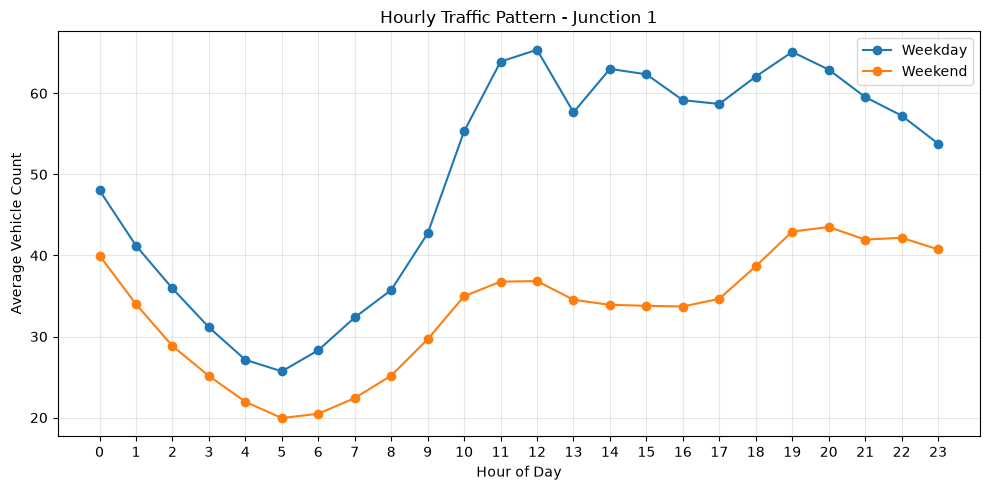

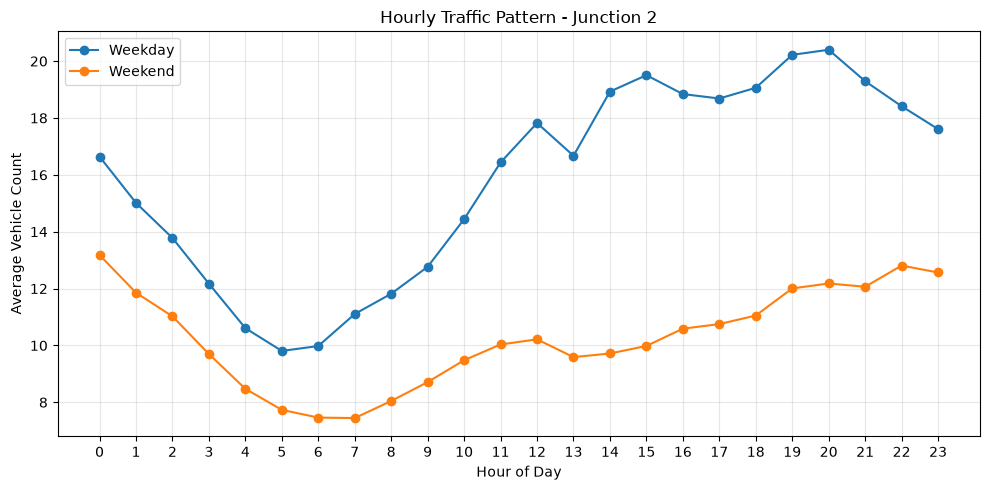

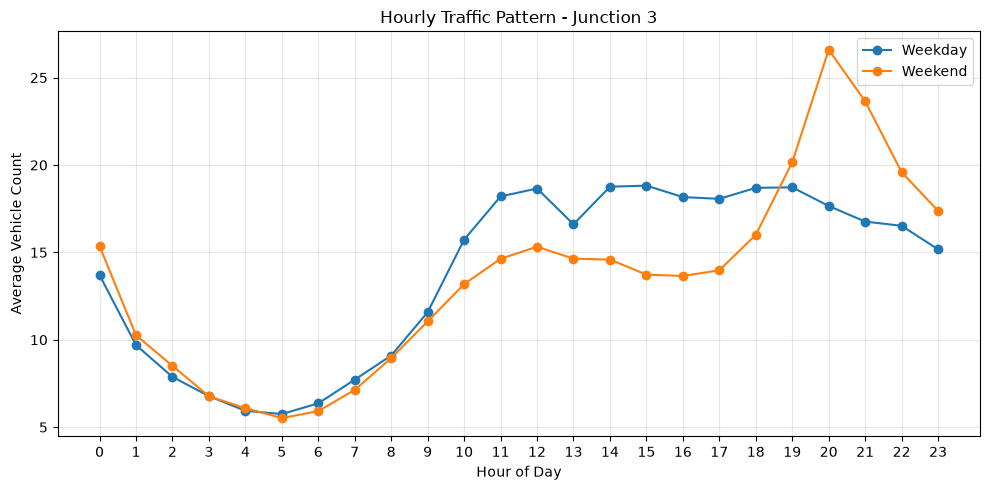

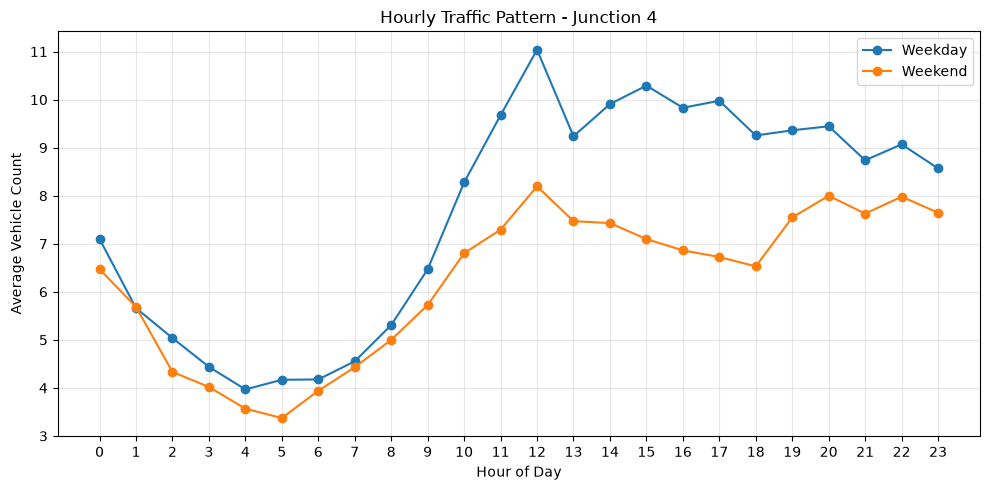

In [33]:
# Plot hourly traffic for weekdays and weekends

for junction in hourly_df[junction_col].dropna().unique():

    junction_data = day_pattern[
        day_pattern[junction_col] == junction
    ]

    plt.figure(figsize=(10, 5))

    for day_type in ["Weekday", "Weekend"]:

        subset = junction_data[
            junction_data["day_type"] == day_type
        ]

        plt.plot(
            subset["hour"],
            subset["average_vehicles"],
            marker="o",
            label=day_type
        )

    plt.title(f"Hourly Traffic Pattern - Junction {junction}")
    plt.xlabel("Hour of Day")
    plt.ylabel("Average Vehicle Count")
    plt.xticks(range(24))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Traffic Patterns by Day of the Week:
junction  day_name  day_of_week  average_vehicles  maximum_vehicles
       1    Monday            0         49.404215               156
       1   Tuesday            1         51.240900               140
       1 Wednesday            2         50.862548               124
       1  Thursday            3         50.284483               132
       1    Friday            4         47.042146               120
       1  Saturday            5         34.111919                82
       1    Sunday            6         32.298372                84
       2    Monday            0         15.228927                47
       2   Tuesday            1         16.556992                48
       2 Wednesday            2         16.416667                47
       2  Thursday            3         16.026341                48
       2    Friday            4         14.942529                41
       2  Saturday            5         10.412791                30
       2   

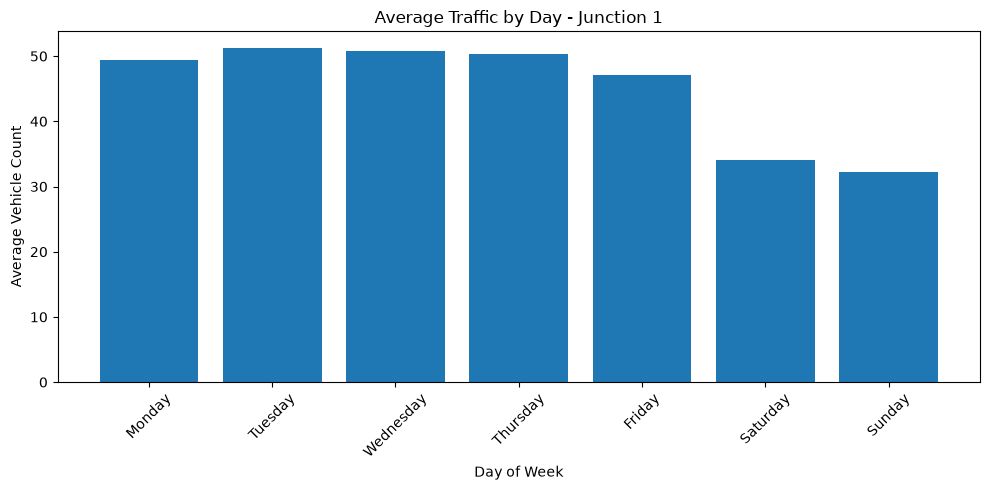

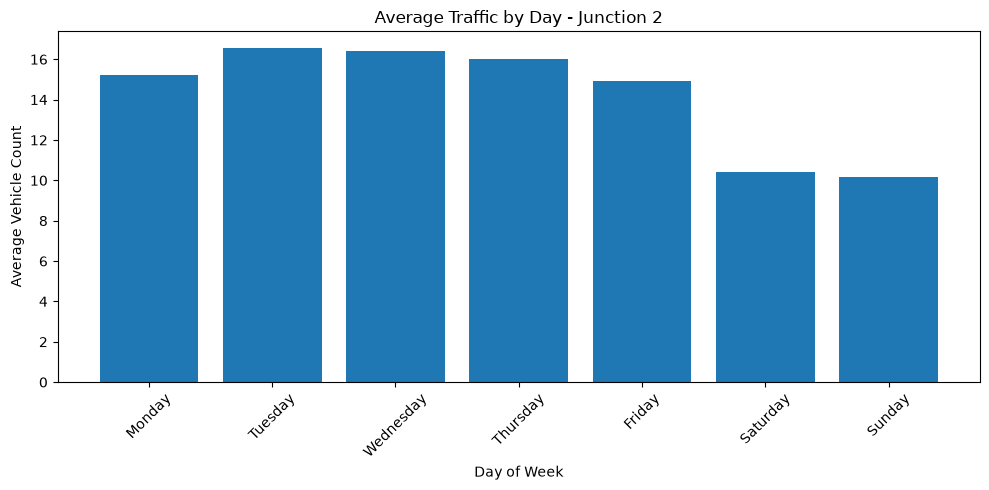

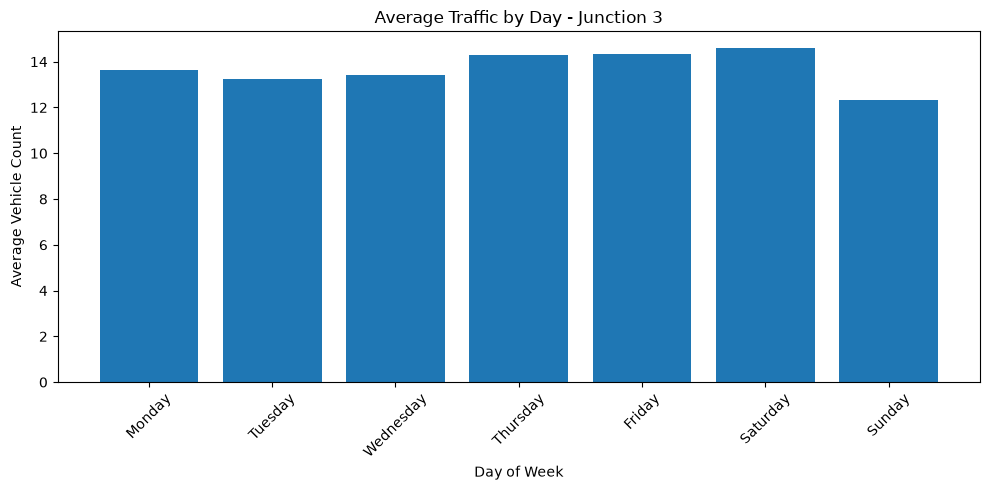

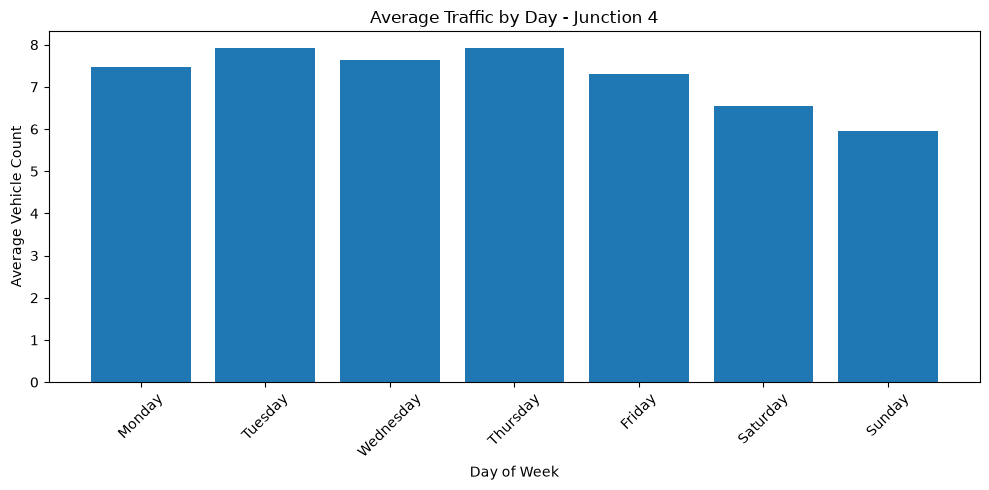

In [34]:
# Compare traffic across days of the week

daily_pattern = (
    hourly_df.groupby(
        [junction_col, "day_name", "day_of_week"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        maximum_vehicles=(vehicle_col, "max")
    )
    .sort_values([junction_col, "day_of_week"])
)

print("Traffic Patterns by Day of the Week:")
print(daily_pattern.to_string(index=False))

# Plot the daily pattern for each junction
for junction in daily_pattern[junction_col].dropna().unique():

    subset = daily_pattern[
        daily_pattern[junction_col] == junction
    ]

    plt.figure(figsize=(10, 5))

    plt.bar(
        subset["day_name"],
        subset["average_vehicles"]
    )

    plt.title(f"Average Traffic by Day - Junction {junction}")
    plt.xlabel("Day of Week")
    plt.ylabel("Average Vehicle Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Monthly Traffic Patterns:
junction  month month_name  average_vehicles  maximum_vehicles
       1      1    January         41.249328               120
       1      2   February         46.000731               156
       1      3      March         46.590054               110
       1      4      April         46.865278               114
       1      5        May         51.899866               136
       1      6       June         55.079167               140
       1      7       July         39.127688                86
       1      8     August         41.915323                81
       1      9  September         47.741667                93
       1     10    October         50.032258               106
       1     11   November         36.776389                96
       1     12   December         36.894489               120
       2      1    January         11.168011                29
       2      2   February         14.532895                40
       2      3      March   

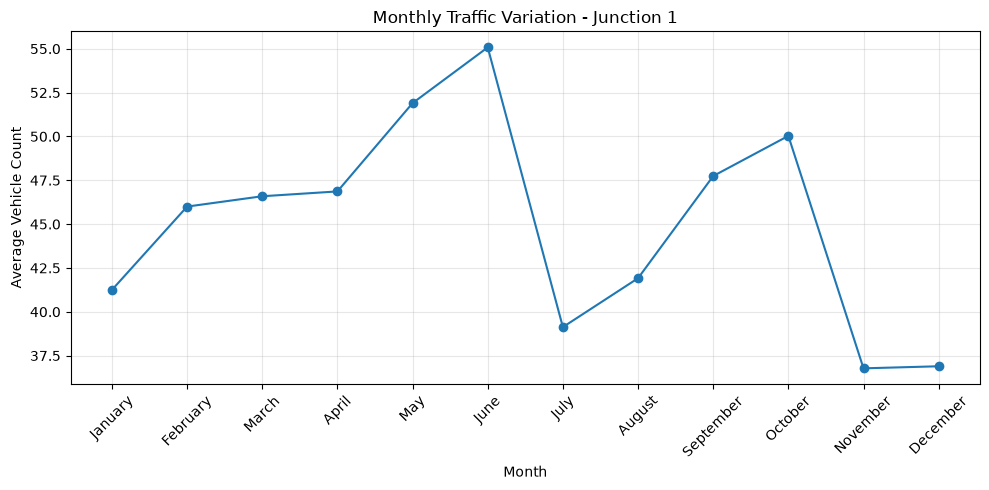

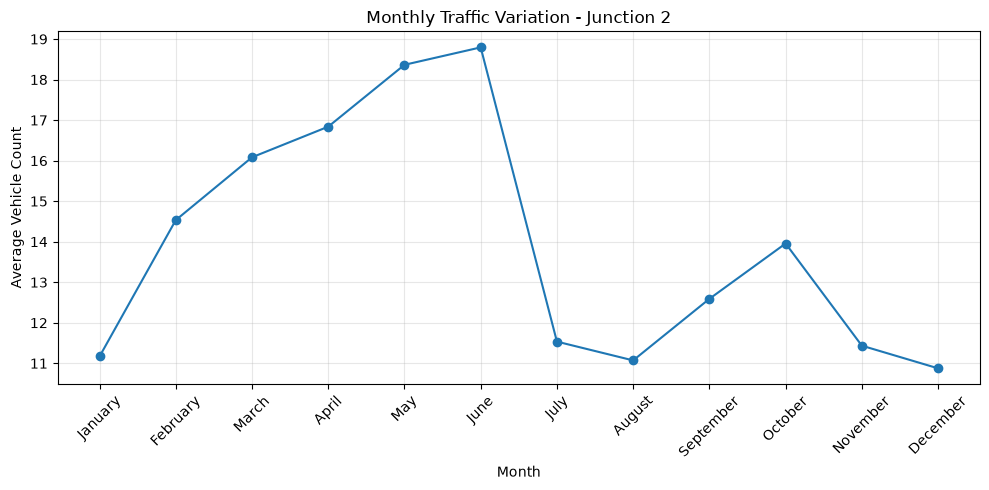

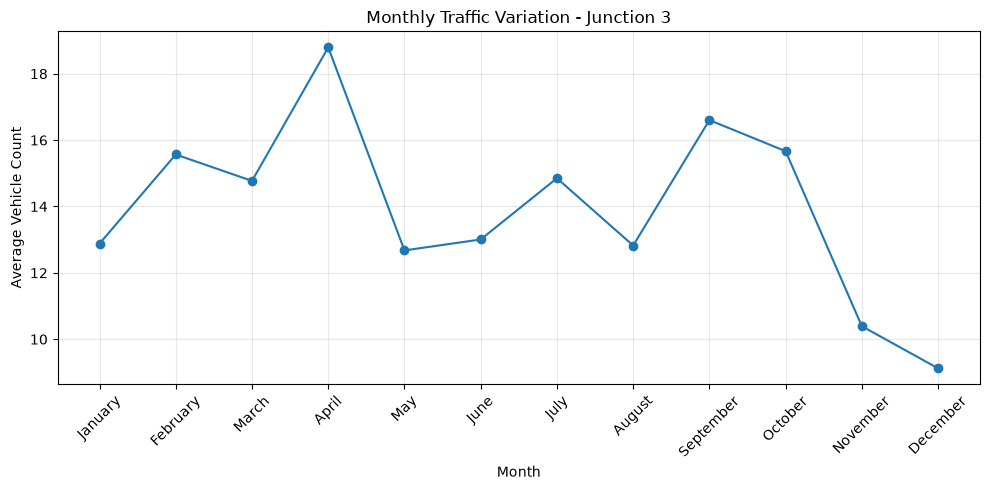

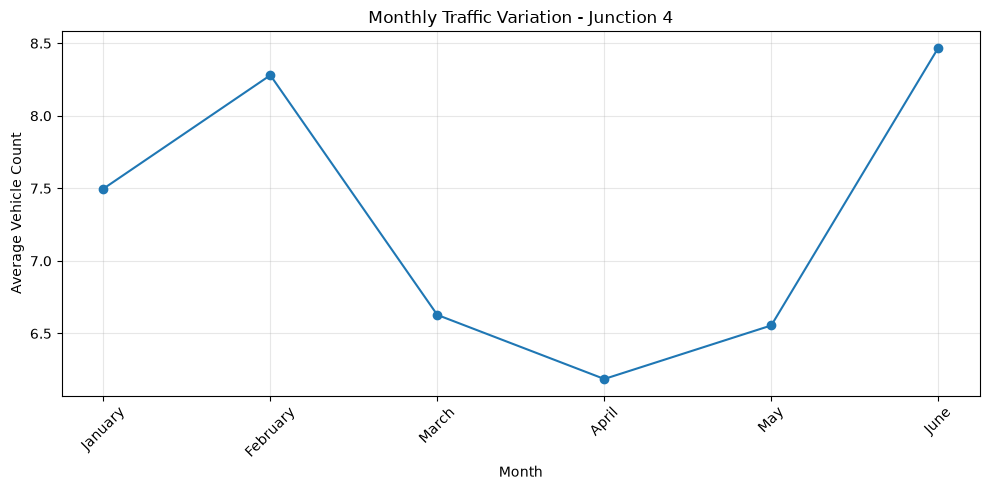

In [35]:
# Calculate monthly traffic statistics

monthly_pattern = (
    hourly_df.groupby(
        [junction_col, "month", "month_name"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        maximum_vehicles=(vehicle_col, "max")
    )
    .sort_values([junction_col, "month"])
)

print("Monthly Traffic Patterns:")
print(monthly_pattern.to_string(index=False))

# Plot monthly traffic variations
for junction in monthly_pattern[junction_col].dropna().unique():

    subset = monthly_pattern[
        monthly_pattern[junction_col] == junction
    ]

    plt.figure(figsize=(10, 5))

    plt.plot(
        subset["month_name"],
        subset["average_vehicles"],
        marker="o"
    )

    plt.title(f"Monthly Traffic Variation - Junction {junction}")
    plt.xlabel("Month")
    plt.ylabel("Average Vehicle Count")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

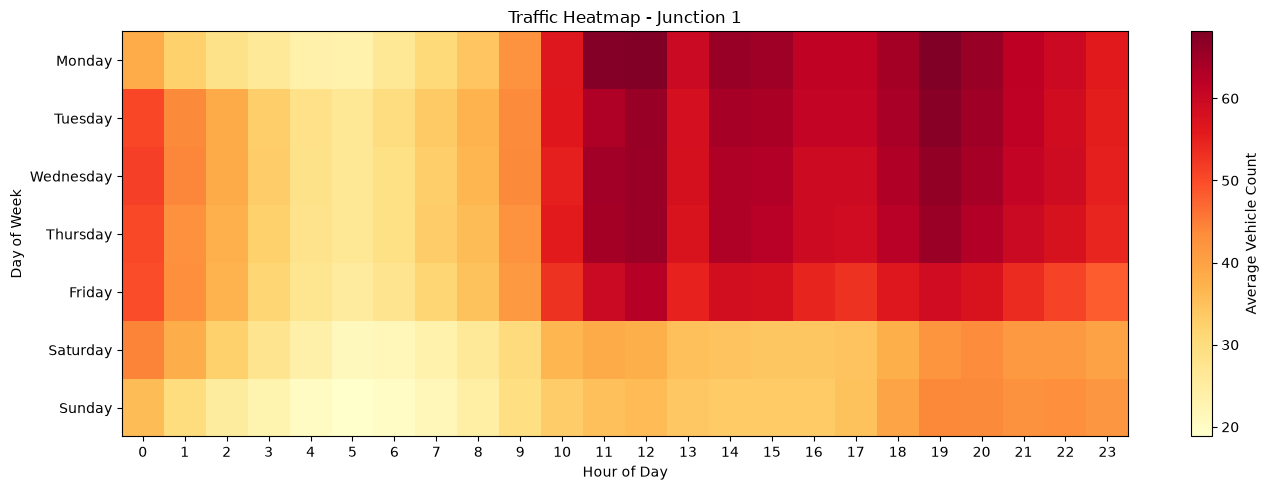

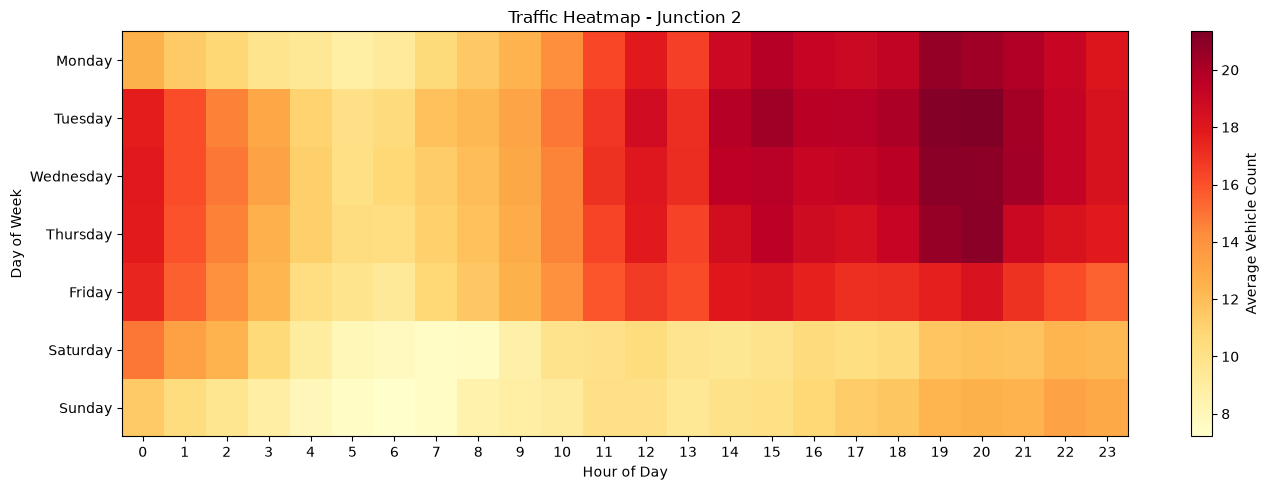

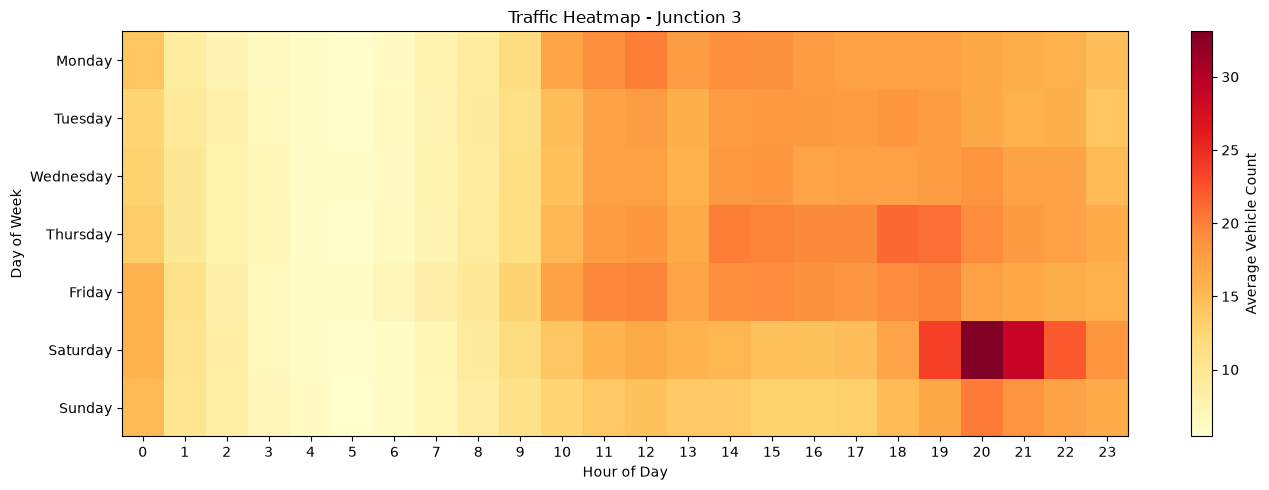

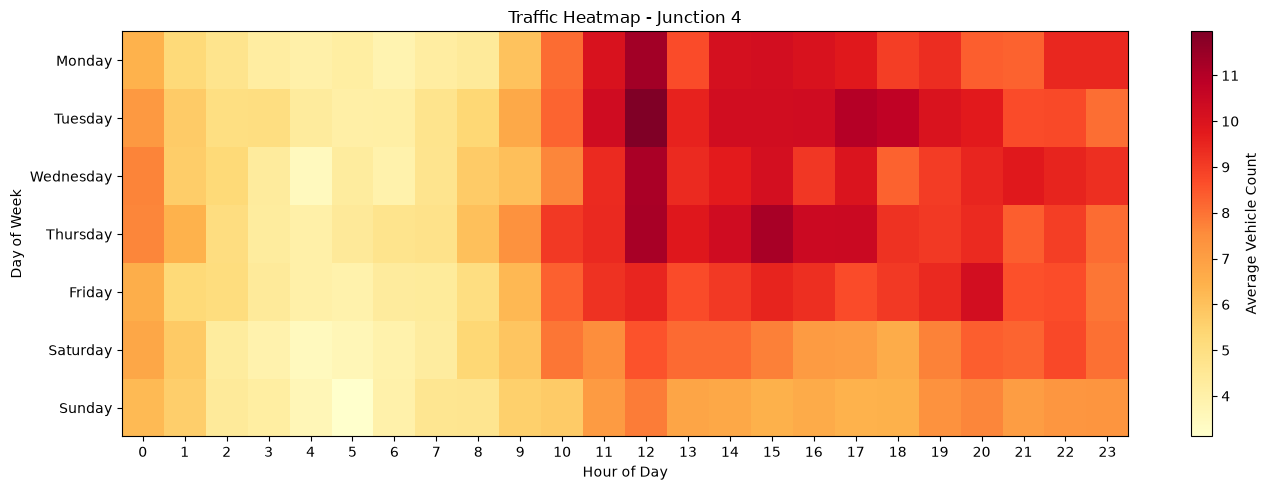

In [36]:
# Create traffic heatmaps

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

for junction in hourly_df[junction_col].dropna().unique():

    subset = hourly_df[
        hourly_df[junction_col] == junction
    ]

    heatmap_data = subset.pivot_table(
        index="day_name",
        columns="hour",
        values=vehicle_col,
        aggfunc="mean"
    )

    heatmap_data = heatmap_data.reindex(day_order)

    plt.figure(figsize=(14, 5))

    plt.imshow(
        heatmap_data,
        aspect="auto",
        cmap="YlOrRd",
        interpolation="nearest"
    )

    plt.colorbar(label="Average Vehicle Count")

    plt.title(f"Traffic Heatmap - Junction {junction}")
    plt.xlabel("Hour of Day")
    plt.ylabel("Day of Week")

    plt.xticks(
        range(len(heatmap_data.columns)),
        heatmap_data.columns
    )

    plt.yticks(
        range(len(heatmap_data.index)),
        heatmap_data.index
    )

    plt.tight_layout()
    plt.show()

In [37]:
# Correlate weather measurements with traffic counts

available_weather = [
    col for col in weather_columns
    if col in hourly_df.columns
]

weather_correlation_results = []

for junction in hourly_df[junction_col].dropna().unique():

    subset = hourly_df[
        hourly_df[junction_col] == junction
    ]

    for weather_col in available_weather:

        valid_data = subset[
            [vehicle_col, weather_col]
        ].dropna()

        # Require enough observations and variation in both columns
        if (
            len(valid_data) >= 3
            and valid_data[vehicle_col].nunique() > 1
            and valid_data[weather_col].nunique() > 1
        ):

            correlation = valid_data[vehicle_col].corr(
                valid_data[weather_col]
            )

            weather_correlation_results.append({
                "junction": junction,
                "weather_variable": weather_col,
                "correlation": correlation,
                "observations": len(valid_data)
            })

weather_correlation_df = pd.DataFrame(
    weather_correlation_results
)

if not weather_correlation_df.empty:

    weather_correlation_df = (
        weather_correlation_df.sort_values(
            "correlation",
            key=abs,
            ascending=False
        )
    )

    print("Weather and Traffic Correlations:")
    print(weather_correlation_df.to_string(index=False))

else:
    print(
        "No valid weather correlations could be calculated. "
        "Check weather column availability and data variation."
    )

Weather and Traffic Correlations:
junction     weather_variable  correlation  observations
       4     temperature_2m_c    -0.217987          4344
       4 relative_humidity_2m     0.163278          4344
       1     temperature_2m_c    -0.101317         14592
       1 relative_humidity_2m     0.084544         14592
       3     temperature_2m_c    -0.063082         14592
       1     precipitation_mm     0.040020         14592
       1              rain_mm     0.040020         14592
       2 relative_humidity_2m     0.029942         14592
       3 relative_humidity_2m     0.026215         14592
       4     precipitation_mm     0.020830          4344
       4              rain_mm     0.020830          4344
       3     precipitation_mm     0.012189         14592
       3              rain_mm     0.012189         14592
       2     temperature_2m_c    -0.012090         14592
       2     precipitation_mm     0.010040         14592
       2              rain_mm     0.010040         145

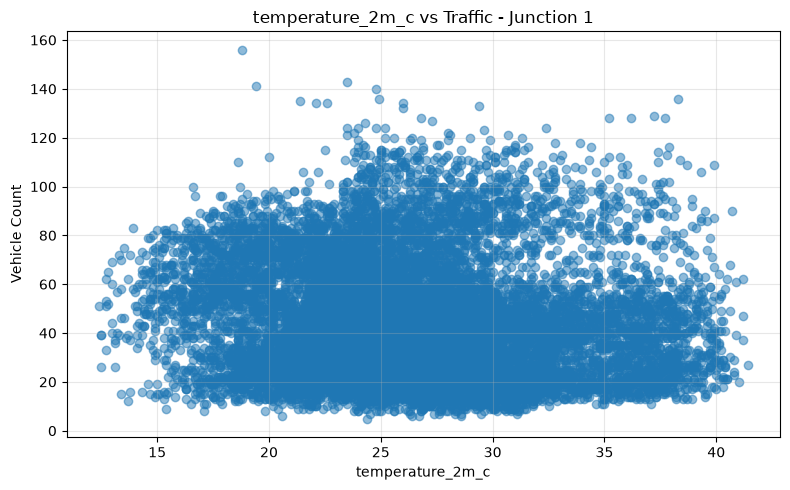

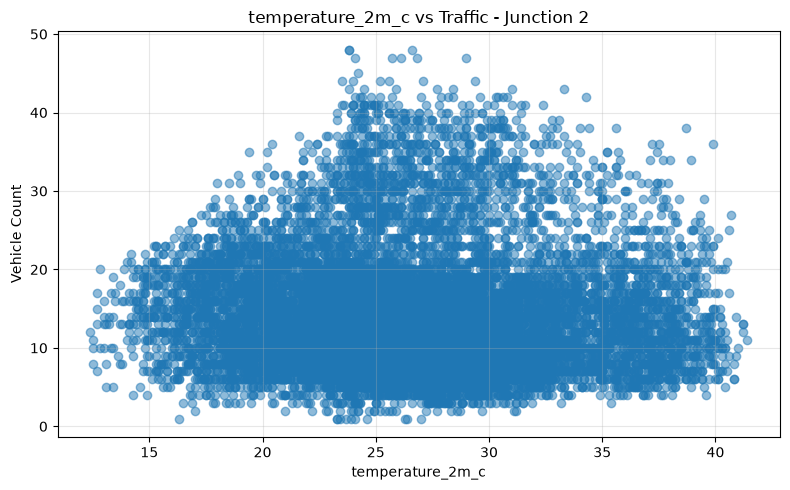

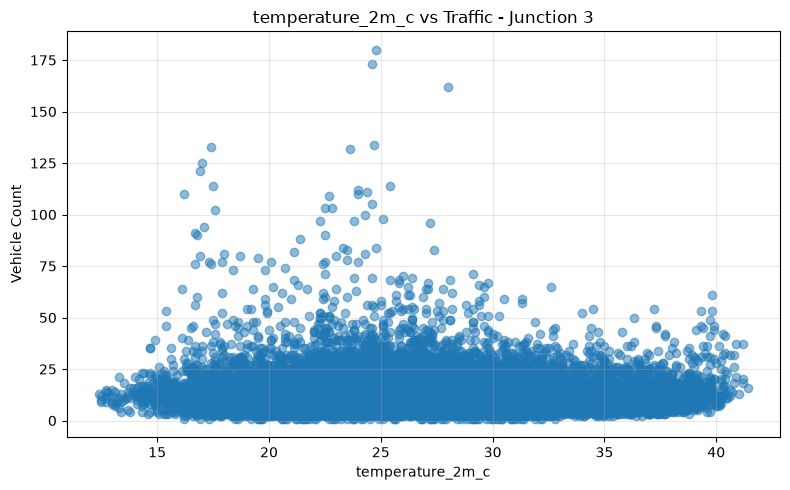

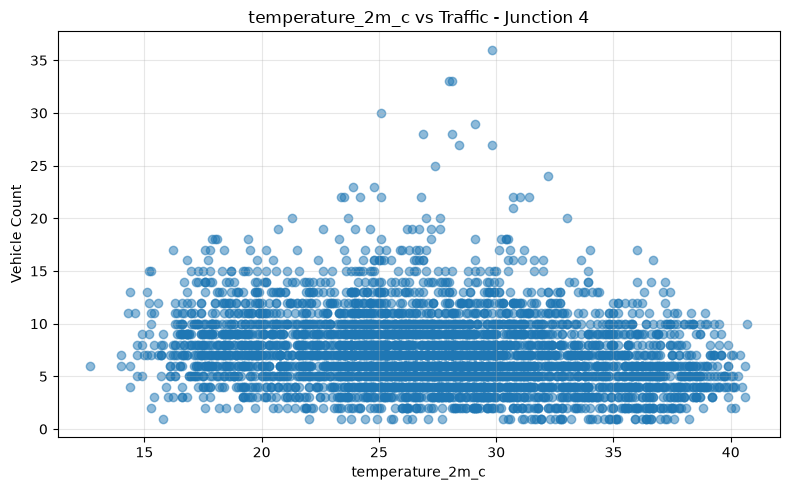

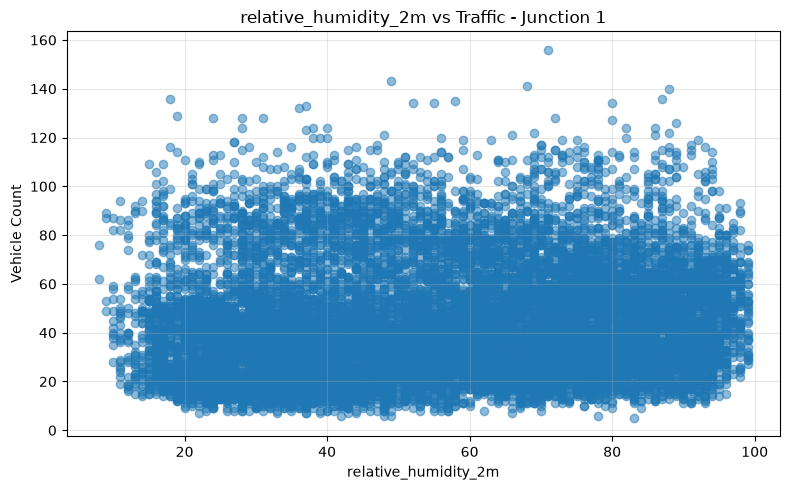

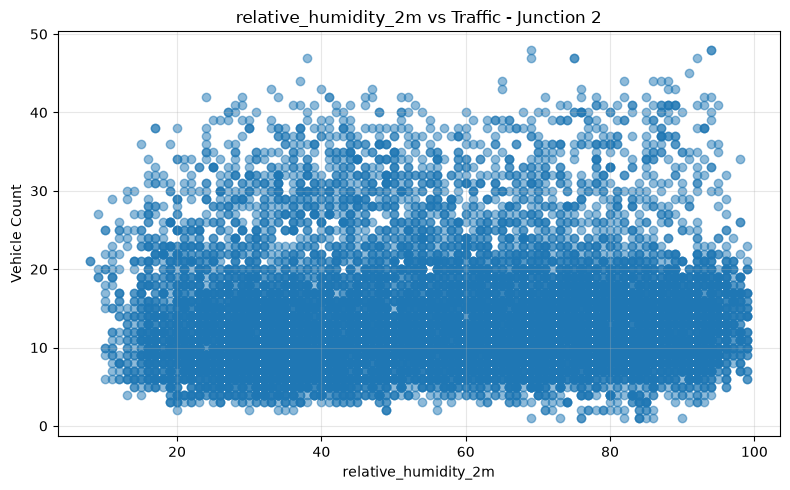

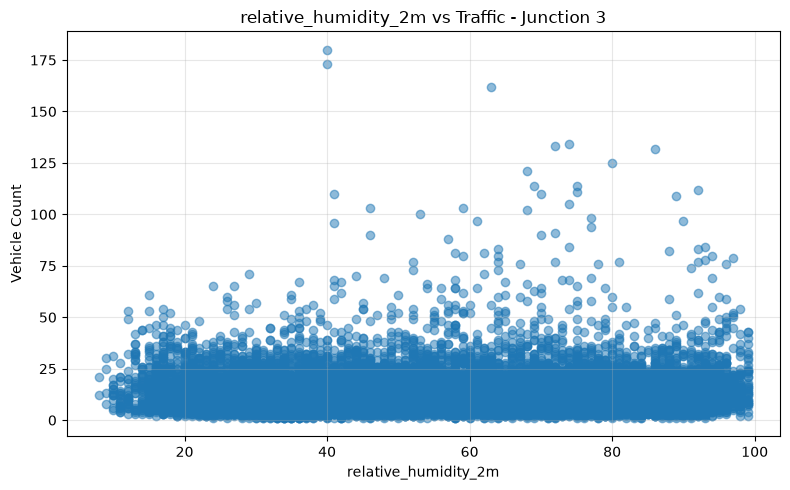

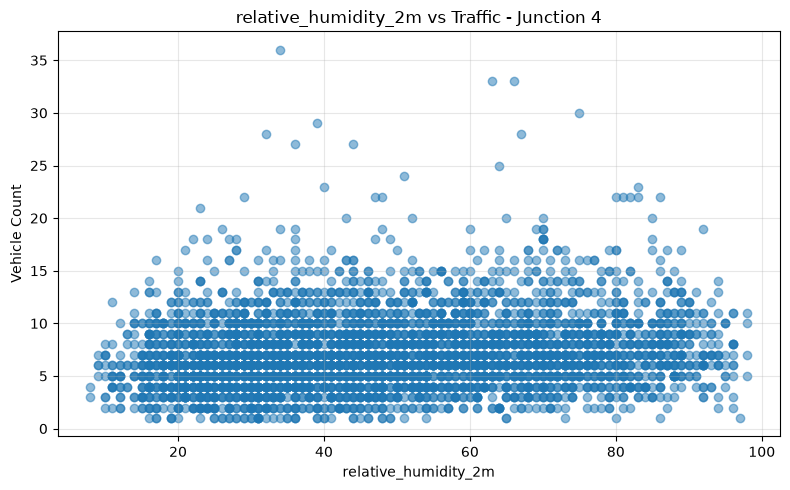

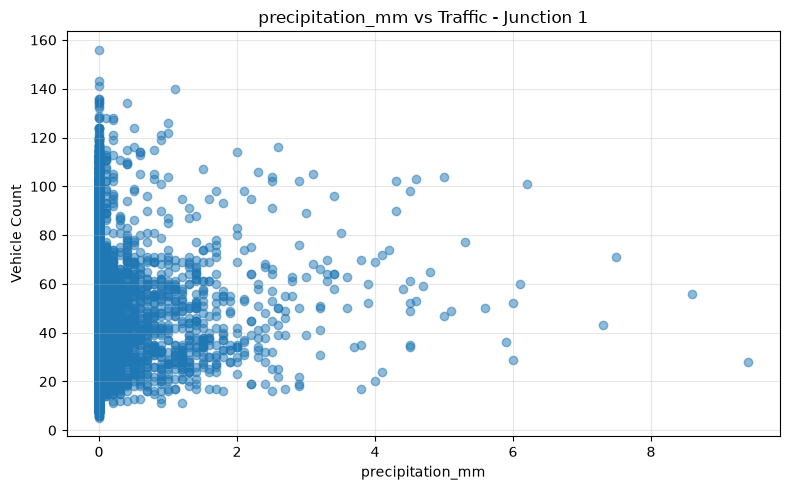

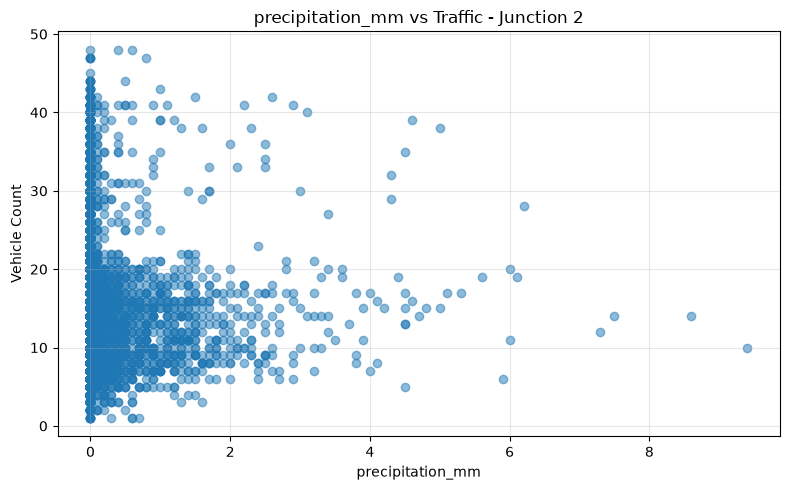

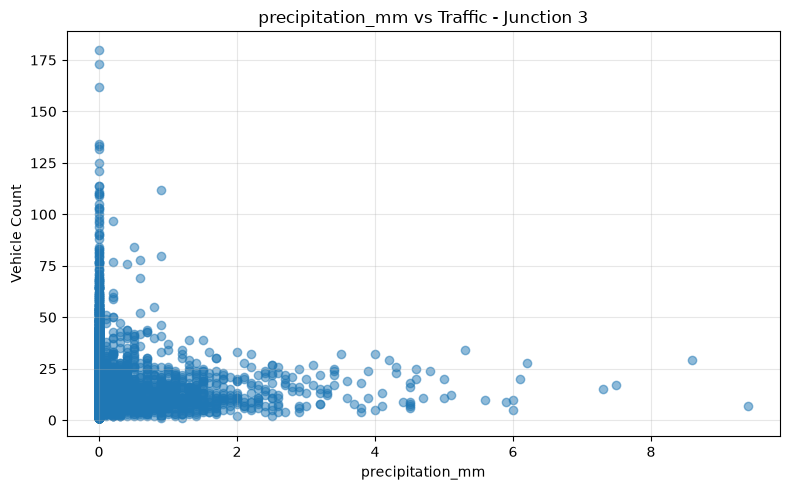

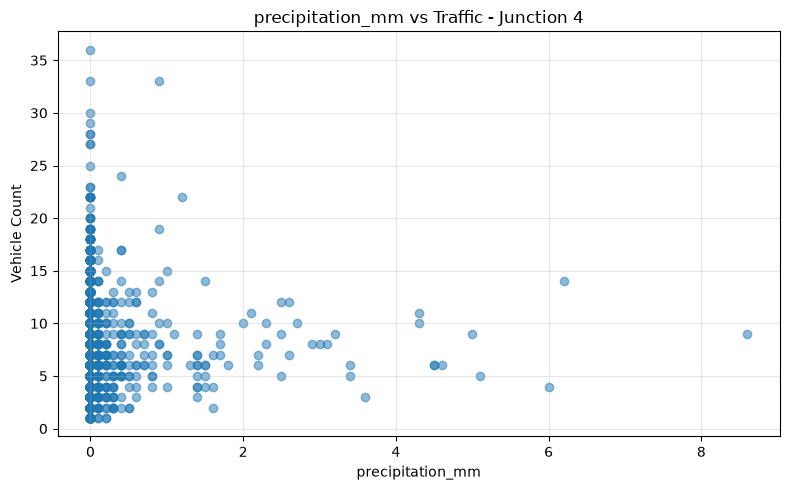

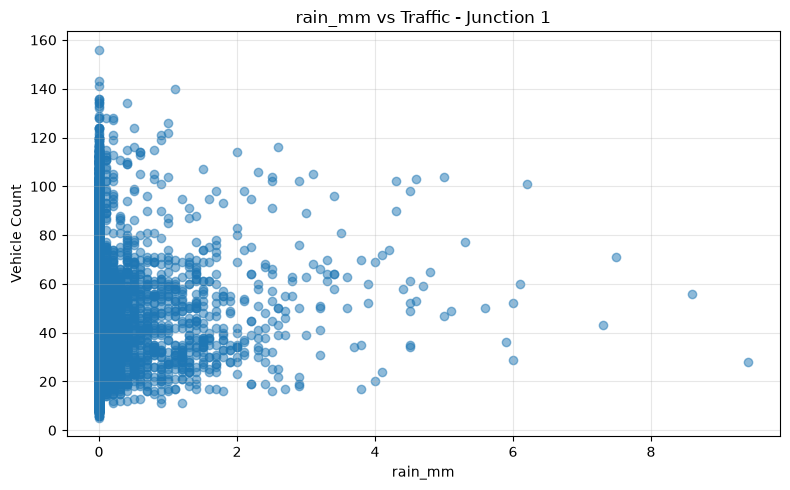

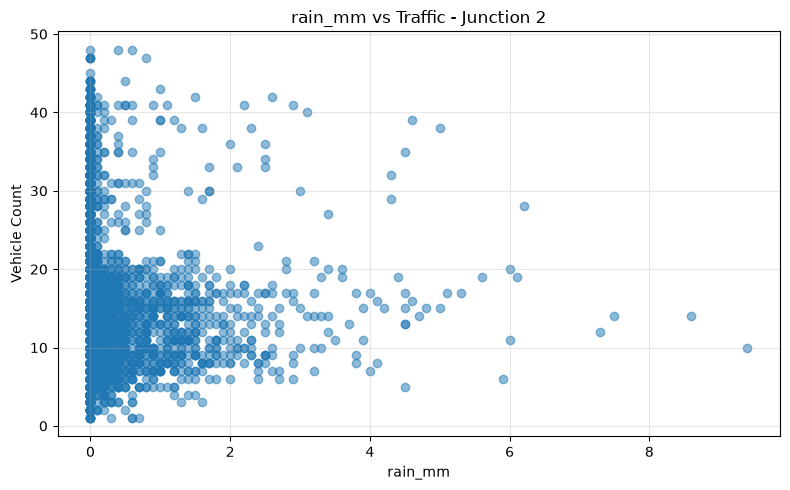

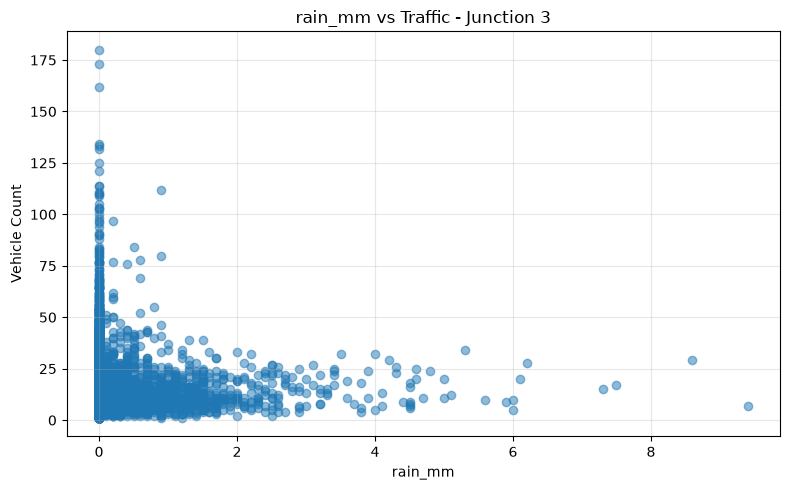

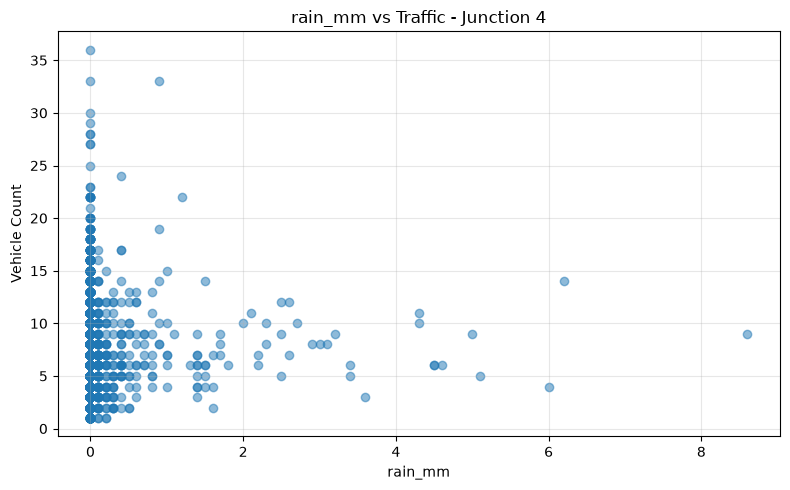

In [38]:
# Create scatter plots of weather measurements and vehicle counts

for weather_col in available_weather:

    for junction in hourly_df[junction_col].dropna().unique():

        subset = hourly_df[
            hourly_df[junction_col] == junction
        ][[vehicle_col, weather_col]].dropna()

        if subset.empty:
            continue

        plt.figure(figsize=(8, 5))

        plt.scatter(
            subset[weather_col],
            subset[vehicle_col],
            alpha=0.5
        )

        plt.title(
            f"{weather_col} vs Traffic - Junction {junction}"
        )

        plt.xlabel(weather_col)
        plt.ylabel("Vehicle Count")

        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

Special Event vs Non-Event Traffic:
junction  is_special_event  average_vehicles  maximum_vehicles  observation_count
       1                 0         45.052906               156              14592
       2                 0         14.253221                48              14592
       3                 0         13.694010               180              14592
       4                 0          7.251611                36               4344


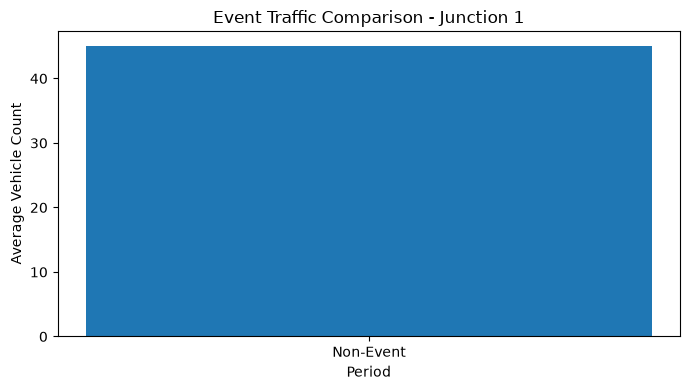

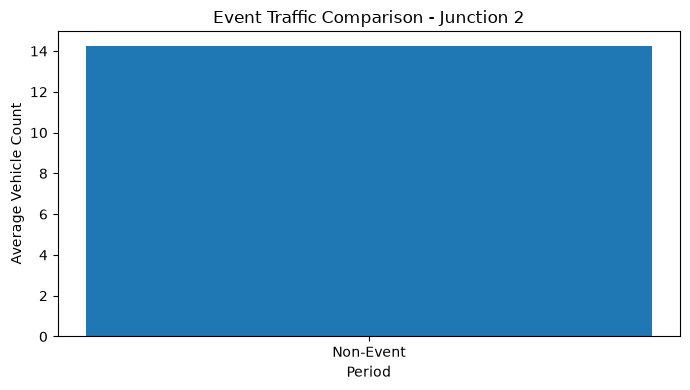

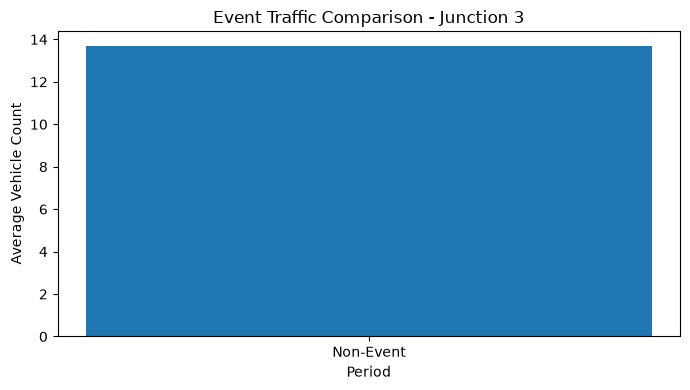

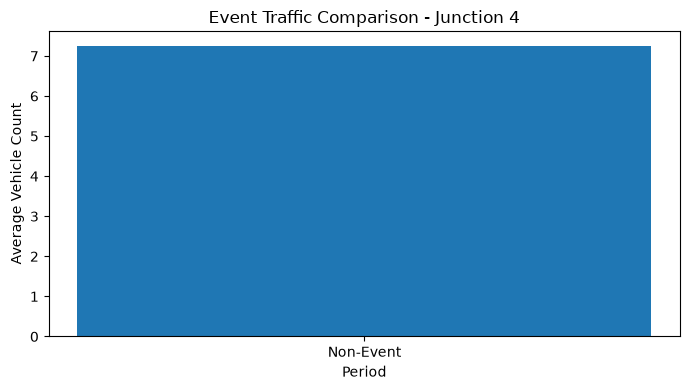

In [39]:
# Compare traffic on special-event and non-event dates

if "is_special_event" not in hourly_df.columns:
    hourly_df["is_special_event"] = 0

event_comparison = (
    hourly_df.groupby(
        [junction_col, "is_special_event"],
        as_index=False
    )
    .agg(
        average_vehicles=(vehicle_col, "mean"),
        maximum_vehicles=(vehicle_col, "max"),
        observation_count=(vehicle_col, "count")
    )
)

print("Special Event vs Non-Event Traffic:")
print(event_comparison.to_string(index=False))

# Plot the comparison for each junction
for junction in hourly_df[junction_col].dropna().unique():

    subset = event_comparison[
        event_comparison[junction_col] == junction
    ]

    if subset.empty:
        continue

    plt.figure(figsize=(7, 4))

    labels = subset["is_special_event"].map({
        0: "Non-Event",
        1: "Special Event"
    })

    plt.bar(
        labels,
        subset["average_vehicles"]
    )

    plt.title(f"Event Traffic Comparison - Junction {junction}")
    plt.xlabel("Period")
    plt.ylabel("Average Vehicle Count")
    plt.tight_layout()
    plt.show()

In [40]:
# Summarize peak hours and traffic patterns by junction

report_rows = []

for junction in hourly_df[junction_col].dropna().unique():

    subset = hourly_df[
        hourly_df[junction_col] == junction
    ]

    hourly_means = (
        subset.groupby("hour")[vehicle_col]
        .mean()
        .sort_values(ascending=False)
    )

    if hourly_means.empty:
        continue

    top_hours = hourly_means.head(3)

    busiest_day = (
        subset.groupby("day_name")[vehicle_col]
        .mean()
        .idxmax()
    )

    busiest_month = (
        subset.groupby("month_name")[vehicle_col]
        .mean()
        .idxmax()
    )

    report_rows.append({
        "junction": junction,
        "average_vehicle_count": round(
            subset[vehicle_col].mean(), 2
        ),
        "maximum_vehicle_count": round(
            subset[vehicle_col].max(), 2
        ),
        "peak_hour_1": int(top_hours.index[0]),
        "peak_hour_2": (
            int(top_hours.index[1])
            if len(top_hours) > 1 else None
        ),
        "peak_hour_3": (
            int(top_hours.index[2])
            if len(top_hours) > 2 else None
        ),
        "busiest_day": busiest_day,
        "busiest_month": busiest_month
    })

peak_hour_report = pd.DataFrame(report_rows)

print("Junction-Wise Peak-Hour Report:")
print(peak_hour_report.to_string(index=False))

Junction-Wise Peak-Hour Report:
junction  average_vehicle_count  maximum_vehicle_count  peak_hour_1  peak_hour_2  peak_hour_3 busiest_day busiest_month
       1                  45.05                    156           19           20           12     Tuesday          June
       2                  14.25                     48           20           19           21     Tuesday          June
       3                  13.69                    180           20           19           21    Saturday         April
       4                   7.25                     36           12           15           14     Tuesday          June


In [41]:
# Generate recommendations based on observed peak traffic

recommendations = []

for junction in hourly_df[junction_col].dropna().unique():

    subset = hourly_df[
        hourly_df[junction_col] == junction
    ]

    hourly_means = (
        subset.groupby("hour")[vehicle_col]
        .mean()
        .sort_values(ascending=False)
    )

    if hourly_means.empty:
        continue

    peak_hour = int(hourly_means.index[0])
    peak_count = hourly_means.iloc[0]
    overall_mean = subset[vehicle_col].mean()

    if peak_count > overall_mean:

        recommendation = (
            f"Review traffic signal timing, turning movements, "
            f"and traffic flow at Junction {junction} around "
            f"{peak_hour:02d}:00. Consider targeted monitoring "
            f"during this high-volume period."
        )

    else:

        recommendation = (
            f"Continue monitoring Junction {junction} to identify "
            f"periods that may require traffic-management changes."
        )

    recommendations.append({
        "junction": junction,
        "peak_hour": f"{peak_hour:02d}:00",
        "peak_average_vehicle_count": round(peak_count, 2),
        "recommendation": recommendation
    })

recommendation_report = pd.DataFrame(recommendations)

print("Preliminary Traffic-Management Recommendations:")
print(recommendation_report.to_string(index=False))

Preliminary Traffic-Management Recommendations:
junction peak_hour  peak_average_vehicle_count                                                                                                                                             recommendation
       1     19:00                       58.80 Review traffic signal timing, turning movements, and traffic flow at Junction 1 around 19:00. Consider targeted monitoring during this high-volume period.
       2     20:00                       18.06 Review traffic signal timing, turning movements, and traffic flow at Junction 2 around 20:00. Consider targeted monitoring during this high-volume period.
       3     20:00                       20.20 Review traffic signal timing, turning movements, and traffic flow at Junction 3 around 20:00. Consider targeted monitoring during this high-volume period.
       4     12:00                       10.24 Review traffic signal timing, turning movements, and traffic flow at Junction 4 around 12:00. Con

In [42]:
model_source = hourly_df.copy()

# Convert the timestamp and target columns to the correct data types
model_source["datetime"] = pd.to_datetime(
    model_source["datetime"], errors="coerce"
)
model_source[vehicle_col] = pd.to_numeric(
    model_source[vehicle_col], errors="coerce"
)

model_source = model_source.dropna(
    subset=["datetime", junction_col, vehicle_col]
).copy()

model_source = model_source.sort_values(
    [junction_col, "datetime"]
).reset_index(drop=True)

# Create time-based features
model_source["hour"] = model_source["datetime"].dt.hour
model_source["day_of_week"] = model_source["datetime"].dt.dayofweek
model_source["day_of_month"] = model_source["datetime"].dt.day
model_source["month"] = model_source["datetime"].dt.month

model_source["is_weekend"] = (
    model_source["day_of_week"] >= 5
).astype(int)

model_source["hour_sin"] = np.sin(
    2 * np.pi * model_source["hour"] / 24
)
model_source["hour_cos"] = np.cos(
    2 * np.pi * model_source["hour"] / 24
)
model_source["month_sin"] = np.sin(
    2 * np.pi * model_source["month"] / 12
)
model_source["month_cos"] = np.cos(
    2 * np.pi * model_source["month"] / 12
)

if "is_special_event" not in model_source.columns:
    model_source["is_special_event"] = 0

# Create lag and rolling features separately for each junction
model_source["traffic_lag_1"] = model_source.groupby(
    junction_col
)[vehicle_col].shift(1)

model_source["traffic_lag_2"] = model_source.groupby(
    junction_col
)[vehicle_col].shift(2)

model_source["traffic_lag_3"] = model_source.groupby(
    junction_col
)[vehicle_col].shift(3)

model_source["traffic_lag_6"] = model_source.groupby(
    junction_col
)[vehicle_col].shift(6)

model_source["traffic_lag_12"] = model_source.groupby(
    junction_col
)[vehicle_col].shift(12)

model_source["traffic_lag_24"] = model_source.groupby(
    junction_col
)[vehicle_col].shift(24)

In [43]:
unique_timestamps = np.sort(
    model_source["datetime"].unique()
)

split_position = int(len(unique_timestamps) * 0.80)

if split_position == 0 or split_position >= len(unique_timestamps):
    raise ValueError(
        "Not enough distinct timestamps for an 80/20 chronological split."
    )

split_timestamp = unique_timestamps[split_position]

train_mask = model_source["datetime"] < split_timestamp
validation_mask = model_source["datetime"] >= split_timestamp

X_train = model_source.loc[train_mask, feature_columns].copy()
y_train = model_source.loc[train_mask, vehicle_col].copy()

X_validation = model_source.loc[
    validation_mask, feature_columns
].copy()
y_validation = model_source.loc[
    validation_mask, vehicle_col
].copy()

train_timestamps = model_source.loc[
    train_mask, "datetime"
].copy()

validation_timestamps = model_source.loc[
    validation_mask, "datetime"
].copy()

print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("Training period:", train_timestamps.min(), "to",
      train_timestamps.max())
print("Validation period:", validation_timestamps.min(), "to",
      validation_timestamps.max())

Training samples: 36444
Validation samples: 11676
Training period: 2015-11-01 00:00:00 to 2017-03-01 08:00:00
Validation period: 2017-03-01 09:00:00 to 2017-06-30 23:00:00


In [49]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_validation)

baseline_mae = mean_absolute_error(
    y_validation, baseline_predictions
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_validation, baseline_predictions)
)
baseline_r2 = r2_score(
    y_validation, baseline_predictions
)

baseline_results = pd.DataFrame([{
    "Model": "Mean Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2": baseline_r2
}])

print(baseline_results.to_string(index=False))

        Model       MAE      RMSE        R2
Mean Baseline 18.922413 27.857516 -0.089667


In [52]:
# Clean training data
train_clean = pd.concat([X_train, y_train.rename("_target")], axis=1)
train_clean = train_clean.replace([np.inf, -np.inf], np.nan).dropna()

X_train_clean = train_clean[X_train.columns]
y_train_clean = train_clean["_target"]

# Clean validation data
validation_clean = pd.concat(
    [X_validation, y_validation.rename("_target")], axis=1
)
validation_clean = validation_clean.replace(
    [np.inf, -np.inf], np.nan
).dropna()

X_validation_clean = validation_clean[X_validation.columns]
y_validation_clean = validation_clean["_target"]

print("Training rows retained:", len(X_train_clean))
print("Validation rows retained:", len(X_validation_clean))

if len(X_train_clean) == 0 or len(X_validation_clean) == 0:
    raise ValueError("No usable rows remain after removing missing values.")

# Train the models
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

random_forest_model.fit(X_train_clean, y_train_clean)
gradient_boosting_model.fit(X_train_clean, y_train_clean)

# Generate predictions
rf_predictions = random_forest_model.predict(X_validation_clean)
gb_predictions = gradient_boosting_model.predict(X_validation_clean)

# Evaluate the models
initial_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_validation_clean, rf_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_validation_clean, rf_predictions)),
        "R2": r2_score(y_validation_clean, rf_predictions)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_validation_clean, gb_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_validation_clean, gb_predictions)),
        "R2": r2_score(y_validation_clean, gb_predictions)
    }
])

print(initial_results.sort_values("MAE").to_string(index=False))

Training rows retained: 36348
Validation rows retained: 11676
            Model      MAE     RMSE       R2
    Random Forest 0.015243 0.145387 0.999970
Gradient Boosting 0.026439 0.133856 0.999975


In [56]:
# Clean training data
train_clean = pd.concat(
    [X_train, y_train.rename("_target")], axis=1
)

train_clean = train_clean.replace(
    [np.inf, -np.inf], np.nan
).dropna()

X_train_clean = train_clean[X_train.columns]
y_train_clean = train_clean["_target"]

# Clean validation data
validation_clean = pd.concat(
    [X_validation, y_validation.rename("_target")], axis=1
)

validation_clean = validation_clean.replace(
    [np.inf, -np.inf], np.nan
).dropna()

X_validation_clean = validation_clean[X_validation.columns]
y_validation_clean = validation_clean["_target"]

print("Training rows:", len(X_train_clean))
print("Validation rows:", len(X_validation_clean))

if len(X_train_clean) == 0 or len(X_validation_clean) == 0:
    raise ValueError("No usable rows remain after cleaning.")

# Get timestamps using the original indices
cv_timestamp_values = model_source.loc[
    X_train_clean.index, "datetime"
].to_numpy()

unique_cv_timestamps = np.sort(
    np.unique(cv_timestamp_values)
)

n_splits = min(3, len(unique_cv_timestamps) - 1)

if n_splits < 2:
    raise ValueError(
        "Not enough distinct timestamps for time-series cross-validation."
    )

time_splitter = TimeSeriesSplit(n_splits=n_splits)
cv_splits = []

for train_idx, test_idx in time_splitter.split(unique_cv_timestamps):
    fold_train_times = unique_cv_timestamps[train_idx]
    fold_test_times = unique_cv_timestamps[test_idx]

    fold_train_rows = np.flatnonzero(
        np.isin(cv_timestamp_values, fold_train_times)
    )
    fold_test_rows = np.flatnonzero(
        np.isin(cv_timestamp_values, fold_test_times)
    )

    if len(fold_train_rows) > 0 and len(fold_test_rows) > 0:
        cv_splits.append((fold_train_rows, fold_test_rows))

rf_parameter_grid = {
    "n_estimators": [100],
    "max_depth": [None],
    "min_samples_leaf": [1, 2]
}

gb_parameter_grid = {
    "n_estimators": [100],
    "learning_rate": [0.05],
    "max_depth": [2, 3]
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rf_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid=gb_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_clean, y_train_clean)
gb_search.fit(X_train_clean, y_train_clean)

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best Random Forest CV MAE:", -rf_search.best_score_)
print()
print("Best Gradient Boosting parameters:", gb_search.best_params_)
print("Best Gradient Boosting CV MAE:", -gb_search.best_score_)

Training rows: 36348
Validation rows: 11676
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}
Best Random Forest CV MAE: 0.0530843340009316

Best Gradient Boosting parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best Gradient Boosting CV MAE: 0.1380194519856266


In [57]:
tuned_rf_model = rf_search.best_estimator_
tuned_gb_model = gb_search.best_estimator_

tuned_rf_predictions = tuned_rf_model.predict(X_validation_clean)
tuned_gb_predictions = tuned_gb_model.predict(X_validation_clean)

tuned_results = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": mean_absolute_error(
            y_validation_clean,
            baseline_model.predict(X_validation_clean)
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_validation_clean,
            baseline_model.predict(X_validation_clean)
        )),
        "R2": r2_score(
            y_validation_clean,
            baseline_model.predict(X_validation_clean)
        )
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(
            y_validation_clean, tuned_rf_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_validation_clean, tuned_rf_predictions
        )),
        "R2": r2_score(y_validation_clean, tuned_rf_predictions)
    },
    {
        "Model": "Tuned Gradient Boosting",
        "MAE": mean_absolute_error(
            y_validation_clean, tuned_gb_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_validation_clean, tuned_gb_predictions
        )),
        "R2": r2_score(y_validation_clean, tuned_gb_predictions)
    }
])

tuned_results = tuned_results.sort_values("MAE").reset_index(drop=True)
print(tuned_results.to_string(index=False))

best_model_name = tuned_results.loc[0, "Model"]

if best_model_name == "Tuned Random Forest":
    best_model = tuned_rf_model
    best_predictions = tuned_rf_predictions
elif best_model_name == "Tuned Gradient Boosting":
    best_model = tuned_gb_model
    best_predictions = tuned_gb_predictions
else:
    best_model = baseline_model
    best_predictions = baseline_model.predict(X_validation_clean)

print("\nBest model based on validation MAE:", best_model_name)

                  Model       MAE      RMSE        R2
    Tuned Random Forest  0.015706  0.145032  0.999970
Tuned Gradient Boosting  0.165375  0.350526  0.999827
          Mean Baseline 18.922413 27.857516 -0.089667

Best model based on validation MAE: Tuned Random Forest


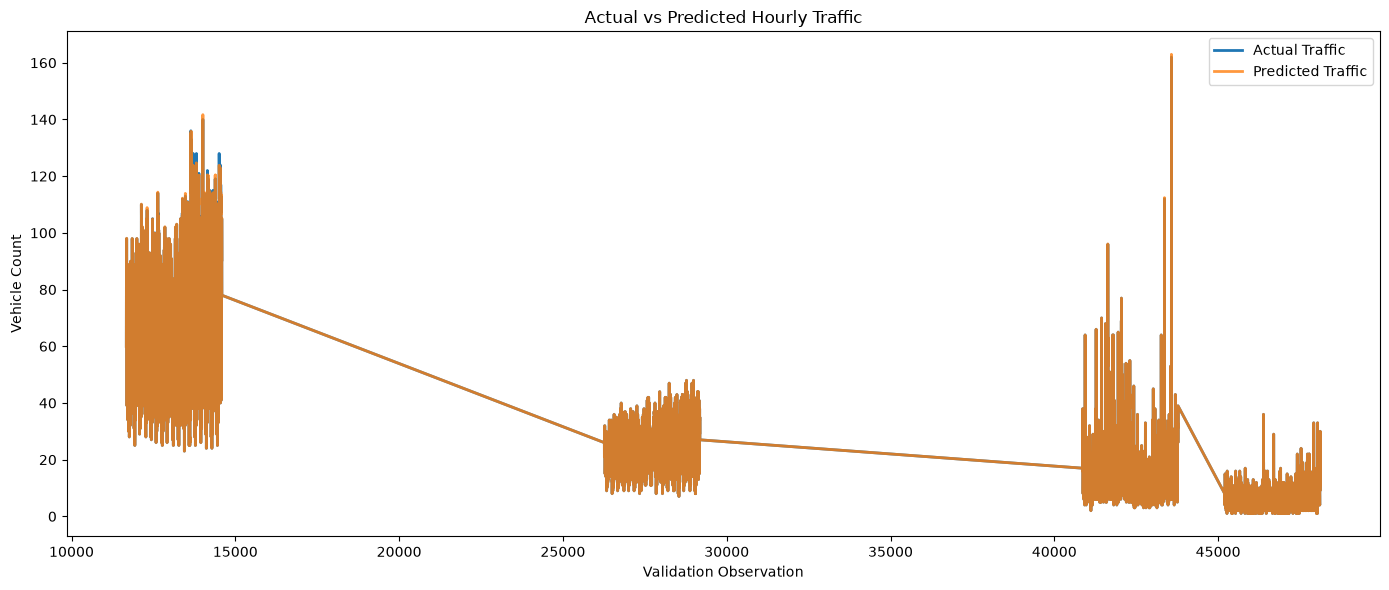

In [58]:
plt.figure(figsize=(14, 6))

plt.plot(
    validation_clean.index,
    y_validation_clean.to_numpy(),
    label="Actual Traffic",
    linewidth=2
)

plt.plot(
    validation_clean.index,
    best_predictions,
    label="Predicted Traffic",
    linewidth=2,
    alpha=0.8
)

plt.title("Actual vs Predicted Hourly Traffic")
plt.xlabel("Validation Observation")
plt.ylabel("Vehicle Count")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
residuals = y_validation_clean.to_numpy() - best_predictions

print("Mean prediction error:", np.mean(residuals))
print("MAE:", mean_absolute_error(y_validation_clean, best_predictions))
print("RMSE:", np.sqrt(mean_squared_error(
    y_validation_clean, best_predictions
)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residuals, bins=30, edgecolor="black")
axes[0].set_title("Distribution of Prediction Errors")
axes[0].set_xlabel("Actual - Predicted")
axes[0].set_ylabel("Frequency")

axes[1].scatter(
    y_validation_clean.to_numpy(),
    best_predictions,
    alpha=0.5
)

plot_min = min(
    y_validation_clean.min(), np.min(best_predictions)
)
plot_max = max(
    y_validation_clean.max(), np.max(best_predictions)
)

axes[1].plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--"
)

axes[1].set_title("Actual vs Predicted Values")
axes[1].set_xlabel("Actual Vehicle Count")
axes[1].set_ylabel("Predicted Vehicle Count")

plt.tight_layout()
plt.show()